# Geração com Seleção por Fitness UV-Vis — Recombinação Zhang–Shasha

Notebook evolutivo baseado em `old/notebook_geracao2_recombinacao_zhang_shasha_MOD_DANIEL.py`.

A principal inovação é a **função FITNESS** no sentido de algoritmos genéticos (AG): após validar as moléculas de cada geração, calculamos um escore de aptidão para cada uma e usamos **seleção por torneio** para escolher quais se tornam sementes da geração seguinte. Moléculas mais aptas têm maior probabilidade de gerar descendentes — mas as menos aptas não são completamente eliminadas, preservando diversidade genética.

A função fitness é construída com base no framework de 6 estágios de **Liu & Liu (IJMS 27:5916, 2026)**:
- **Estágio 1** (corretude molecular): já garantido pela validação de SMILES.
- **Estágio 2** (viabilidade químico-farmacêutica): MW, QED, SA score, TPSA, logP, filtro PAINS — adaptados para corantes UV-Vis.
- **Indicadores UV-Vis específicos**: sistema π (anéis aromáticos / ligações conjugadas), arquitetura D-π-A (grupos doadores e aceptores), planaridade.

O loop encerra quando uma geração inteira não produz nenhuma molécula nova (convergência natural), ou ao atingir o teto de segurança.

## 1. Dependências

In [29]:
# %pip install rdkit
# %pip install zss

In [30]:
import random
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from rdkit import Chem
from rdkit.Chem import Descriptors, QED
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from zss import Node, simple_distance

random.seed(42)
np.random.seed(42)

# ── SA Score (acessibilidade sintética) ─────────────────────────────────────
# Tenta importar via rdkit.Contrib (RDKit >= 2022) e cai para path manual.
_SA_DISPONIVEL = False
_sascorer = None
try:
    from rdkit.Contrib.SA_Score import sascorer as _sascorer  # type: ignore[import]
    _SA_DISPONIVEL = True
except ImportError:
    try:
        from rdkit.Chem import RDConfig
        sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
        import sascorer as _sascorer  # type: ignore[import]
        _SA_DISPONIVEL = True
    except ImportError:
        print('⚠  sascorer não encontrado — SA score será fixado em 5.0 (neutro).')

# ── Filtro PAINS ─────────────────────────────────────────────────────────────
_params_pains = FilterCatalogParams()
_params_pains.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
CATALOGO_PAINS = FilterCatalog(_params_pains)

print('Dependências carregadas.')
print(f'SA score disponível: {_SA_DISPONIVEL}')

Dependências carregadas.
SA score disponível: True


## 2. Carregar a base já validada

In [31]:
CAMINHO_BASE = 'C://Users//Cliente//Documents//Git//gerador_smiles//data//banco_smiles_aromatizados.parquet'

df_base = pd.read_parquet(CAMINHO_BASE)

print(f'Moléculas na base de entrada: {len(df_base):,}')
print(f'Colunas disponíveis:          {df_base.shape[1]}')
display(df_base.head(3))

canonicos_base_complexo = set(df_base['SMILES_Canonico_Complexo'].dropna())

canonicos_base_aromatico = set()
for smi in df_base['smiles'].dropna():
    mol = Chem.MolFromSmiles(str(smi))
    if mol is not None:
        canonicos_base_aromatico.add(Chem.MolToSmiles(mol, canonical=True))

print(f'//nSMILES canônicos (complexo) na base:  {len(canonicos_base_complexo):,}')
print(f'SMILES canônicos (aromático) na base: {len(canonicos_base_aromatico):,}')

Moléculas na base de entrada: 5,974
Colunas disponíveis:          34


,id_Anel1,ID_Anel_Anel1,SMILES_Base_Anel1,SMILES_Modificado_Anel1,ID_Frag_1_Anel1,Frag_Estrutura_1_Anel1,Posicao_1_Anel1,ID_Frag_2_Anel1,Frag_Estrutura_2_Anel1,Posicao_2_Anel1,...,Frag_Estrutura_2_Anel2,Posicao_2_Anel2,ID_Frag_3_Anel2,Frag_Estrutura_3_Anel2,Posicao_3_Anel2,SMILES_Canonico_Fragmento_Anel2,SMILES_Complexo,SMILES_Canonico_Complexo,SMILES_Aromatico,smiles
0,319,2,C1CCCCC1,C1(N)C(Br)CCC(N(C)C)C1,11,N,2,21,Br,3,...,C(=O)OCC,4,14,C(=O)O,6,CCOC(=O)C1CC(CC)CC(C(=O)O)N1,C1(N)C(Br)CCC(N(C)C)C1C=CC=CC=CC=CC2(CC)CC(C(=...,CCOC(=O)C1CC(C=CC=CC=CC=CC2C(N)C(Br)CCC2N(C)C)...,CCOC(=O)C1:C:C(C=CC=CC=CC=CC2:C(N(C)C):C:C:C(B...,CCOC(=O)C1:C:C(C=CC=CC=CC=CC2:C(N(C)C):C:C:C(B...
1,8848,45,S1SCCCC1,S1(C(F)(F)F)S(N(CC)CC)CC(NCC)CC1,17,C(F)(F)F,2,9,N(CC)CC,3,...,OC,3,21,Br,6,COC1CSC(Br)CC1C(F)(F)F,S1(C(F)(F)F)S(N(CC)CC)CC(NCC)CC1C#CC2(C(F)(F)F...,CCNC1CC(C#CC2(C(F)(F)F)CC(Br)SCC2OC)[SH](C(F)(...,CCNC1:C:C(C#CC2(C(F)(F)F):C:C(Br):S:C:C:2OC):S...,CCNC1:C:C(C#CC2(C(F)(F)F):C:C(Br):S:C:C:2OC):S...
2,2142,11,C1CNCCC1,C1CN(Br)C(C(=O)OCC)C(NCC)C1,21,Br,4,18,C(=O)OCC,5,...,N=O,4,20,[O][Na],5,O=N[SH]1C(O)CCCC1[O][Na],C1CN(Br)C(C(=O)OCC)C(NCC)C1C(=N)C2C(O)S(N=O)C(...,CCNC1C(C(=N)C2CCC([O][Na])[SH](N=O)C2O)CCN(Br)...,CCNC1:C(C(=N)C2:C:C:C([O][Na]):S(N=O):C:2O):C:...,CCNC1:C(C(=N)C2:C:C:C([O][Na]):S(N=O):C:2O):C:...


[08:33:22] Can't kekulize mol.  Unkekulized atoms: 5 6 29 30 34
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 3 4 18 19 22
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 18 19 20 22 23
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 4 5 9 10 13
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 3 4 8 9 30
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 10 11 14 16 21
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 23 24 29 32
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 24 25 27 29
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 5 6 11 14 15
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 6 9 10 13
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 11 12 13 20 21
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 26
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 7 8 9
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 12 13 16 17 18
[08:33:22] Can't kekulize mol.  Unkekulized atoms: 5 6 9 14 15
[08:33:22] Can't kekulize mol.  Unkekulized atoms:

//nSMILES canônicos (complexo) na base:  5,974
SMILES canônicos (aromático) na base: 2,573


[08:33:24] Can't kekulize mol.  Unkekulized atoms: 9 10 13 18 19
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 17 18 19 23 33
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 13 14 15 19 21
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 17 18 19 23 24
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 2 3 10 11 16
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 1 3 5 6
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 14 15 16 18 21
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 19 26 27 28
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 4 5 6 28
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 3 4 25 28
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 5 6 25 26 30
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 2 3 8 10 28
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 19 20 22 26 27
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 3 4 29 33 34
[08:33:24] Can't kekulize mol.  Unkekulized atoms: 5 6 7 27 28
[08:33:24] Can't kekulize mol.  Unkekulized 

## 3. Catálogo de anéis

Cada linha da base guarda dois anéis recombinados (`Anel1` e `Anel2`).
Tratamos cada anel como peça reaproveitável — matéria-prima para novas recombinações.

In [32]:
def extrair_catalogo_aneis(df, sufixo):
    colunas = {
        'base':              f'SMILES_Base_Anel{sufixo}',
        'smiles_modificado': f'SMILES_Modificado_Anel{sufixo}',
        'frag1': f'Frag_Estrutura_1_Anel{sufixo}', 'pos1': f'Posicao_1_Anel{sufixo}',
        'frag2': f'Frag_Estrutura_2_Anel{sufixo}', 'pos2': f'Posicao_2_Anel{sufixo}',
        'frag3': f'Frag_Estrutura_3_Anel{sufixo}', 'pos3': f'Posicao_3_Anel{sufixo}',
    }
    sub = df[list(colunas.values())].copy()
    sub.columns = list(colunas.keys())
    sub['origem'] = f'Anel{sufixo}'
    return sub


catalogo_bruto = pd.concat(
    [extrair_catalogo_aneis(df_base, 1), extrair_catalogo_aneis(df_base, 2)],
    ignore_index=True,
)
catalogo_aneis = (
    catalogo_bruto.drop_duplicates(subset='smiles_modificado').reset_index(drop=True)
)

print(f'Anéis extraídos (Anel1+Anel2, com repetição): {len(catalogo_bruto):,}')
print(f'Anéis únicos no catálogo:                      {len(catalogo_aneis):,}')
display(catalogo_aneis.head(3))

Anéis extraídos (Anel1+Anel2, com repetição): 11,948
Anéis únicos no catálogo:                      5,254


,base,smiles_modificado,frag1,pos1,frag2,pos2,frag3,pos3,origem
0,C1CCCCC1,C1(N)C(Br)CCC(N(C)C)C1,N,2,Br,3,N(C)C,6,Anel1
1,S1SCCCC1,S1(C(F)(F)F)S(N(CC)CC)CC(NCC)CC1,C(F)(F)F,2,N(CC)CC,3,NCC,5,Anel1
2,C1CNCCC1,C1CN(Br)C(C(=O)OCC)C(NCC)C1,Br,4,C(=O)OCC,5,NCC,6,Anel1


## 4. Catálogo de pontes

In [33]:
catalogo_pontes = (
    df_base[['ID_Ponte', 'Ponte_Estrutura']]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)
catalogo_pontes = catalogo_pontes[
    catalogo_pontes['Ponte_Estrutura'].str.strip() != '#ERROR!'
].reset_index(drop=True)

print(f'Pontes distintas disponíveis: {len(catalogo_pontes):,}')
display(catalogo_pontes)
catalogo_pontes_lista = catalogo_pontes.to_dict('records')

Pontes distintas disponíveis: 20


,ID_Ponte,Ponte_Estrutura
0,17,C=CC=CC=CC=C
1,11,C#C
2,19,C(=N)
3,1,N=N
4,13,C=CC=C
5,6,C=
6,12,C#CC#C
7,16,C=CC=CC=C
8,20,C=C(C)C=C
9,9,-


## 5. Árvores Zhang–Shasha (TED)

A diversidade estrutural dos pares recombinados continua sendo guiada pela **Tree Edit Distance** (TED) normalizada — mantida do notebook original. O TED guia *com quem* cada molécula se recombina; o fitness decide *quem vira semente*.

In [34]:
def valor_valido(v):
    return pd.notna(v) and str(v).strip() not in {'', 'nan', 'None'}


def anel_para_arvore(row):
    raiz = Node(f"ANEL:{row['base']}")
    itens = []
    for slot in (1, 2, 3):
        frag = row[f'frag{slot}']
        pos  = row[f'pos{slot}']
        if valor_valido(frag):
            itens.append((str(pos), str(frag)))
    for pos, frag in sorted(itens, key=lambda x: x[0]):
        no_pos = Node(f'POS:{pos}')
        no_pos.addkid(Node(f'FRAG:{frag}'))
        raiz.addkid(no_pos)
    return raiz


def tamanho_arvore(no):
    return 1 + sum(tamanho_arvore(filho) for filho in no.children)


def ted_normalizada(a, b):
    d = simple_distance(a, b)
    denom = max(tamanho_arvore(a), tamanho_arvore(b), 1)
    return d / denom


arvores_catalogo = [anel_para_arvore(row) for _, row in catalogo_aneis.iterrows()]
print(f'Árvores construídas para o catálogo completo: {len(arvores_catalogo):,}')

Árvores construídas para o catálogo completo: 5,254


## 6. Funções de recombinação e validação

Mesmas funções do notebook original: `substituir_numeracao_anel`, `validar_e_canonizar`, `aromatizar_aneis_6_membros`. Também o mapa de colunas que reencaixa o resultado de uma geração no formato do histórico.

In [35]:
def substituir_numeracao_anel(smiles, de='1', para='2'):
    return smiles.replace(de, para)


def validar_e_canonizar(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None, False
    return Chem.MolToSmiles(mol, canonical=True), True


def aromatizar_aneis_6_membros(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    for anel in mol.GetRingInfo().AtomRings():
        if len(anel) != 6:
            continue
        for k in range(len(anel)):
            at1, at2 = anel[k], anel[(k + 1) % len(anel)]
            lig = mol.GetBondBetweenAtoms(at1, at2)
            if lig is None:
                return None
            lig.SetBondType(Chem.rdchem.BondType.AROMATIC)
        for idx in anel:
            mol.GetAtomWithIdx(idx).SetIsAromatic(True)
    try:
        Chem.SanitizeMol(mol)
    except Exception:
        return None
    return Chem.MolToSmiles(mol)


MAPA_COLUNAS = {
    'base_Anel1': 'SMILES_Base_Anel1',
    'smiles_modificado_Anel1': 'SMILES_Modificado_Anel1',
    'frag1_Anel1': 'Frag_Estrutura_1_Anel1', 'pos1_Anel1': 'Posicao_1_Anel1',
    'frag2_Anel1': 'Frag_Estrutura_2_Anel1', 'pos2_Anel1': 'Posicao_2_Anel1',
    'frag3_Anel1': 'Frag_Estrutura_3_Anel1', 'pos3_Anel1': 'Posicao_3_Anel1',
    'base_Anel2': 'SMILES_Base_Anel2',
    'smiles_modificado_Anel2': 'SMILES_Modificado_Anel2',
    'frag1_Anel2': 'Frag_Estrutura_1_Anel2', 'pos1_Anel2': 'Posicao_1_Anel2',
    'frag2_Anel2': 'Frag_Estrutura_2_Anel2', 'pos2_Anel2': 'Posicao_2_Anel2',
    'frag3_Anel2': 'Frag_Estrutura_3_Anel2', 'pos3_Anel2': 'Posicao_3_Anel2',
}

print('Funções de validação definidas.')

Funções de validação definidas.


## 7. Função FITNESS UV-Vis

Baseada no framework de 6 estágios de **Liu & Liu (IJMS 27:5916, 2026)**.

### 7.1 Padrões SMARTS para grupos UV-Vis

Grupos **doadores (D)**: aumentam densidade eletrônica no cromóforo → red-shift batocrômico.
Grupos **aceptores (A)**: retiram densidade eletrônica; junto com D formam a arquitetura D-π-A.
Grupos **cromóforos conjugados**: criam o caminho de deslocalização π (ex.: azo, estirila).

In [36]:
_DOADORES = {
    'amino_primario':   Chem.MolFromSmarts('[NX3;H2]'),
    'amino_secundario': Chem.MolFromSmarts('[NX3;H1;!$(NC=O)]'),
    'amino_terciario':  Chem.MolFromSmarts('[NX3;H0;!$(NC=O);!$(N=*)]'),
    'hidroxil':         Chem.MolFromSmarts('[OX2H]'),
    'alcoxil':          Chem.MolFromSmarts('[OX2;!$(OC=O)][#6]'),
    'tiol':             Chem.MolFromSmarts('[SX2H]'),
    'tioeter':          Chem.MolFromSmarts('[SX2;!$(SC=O)][#6]'),
}

_ACEPTORES = {
    'nitro':    Chem.MolFromSmarts('[N+](=O)[O-]'),
    'nitroso':  Chem.MolFromSmarts('[NX2]=O'),
    'ciano':    Chem.MolFromSmarts('[CX2]#[NX1]'),
    'carbonil': Chem.MolFromSmarts('[CX3](=O)[#6]'),
    'sulfonil': Chem.MolFromSmarts('[SX4](=O)(=O)'),
    'imina':    Chem.MolFromSmarts('[CX3]=[NX2]'),
}

_CROMOFOROS = {
    'azo':     Chem.MolFromSmarts('[NX2]=[NX2]'),     # -N=N- (azo)
    'vinil':   Chem.MolFromSmarts('[#6]=[#6]'),        # C=C conjugado
    'estiril': Chem.MolFromSmarts('c[CX3]=[CX3]'),    # Ar-CH=CH-
    'quinona': Chem.MolFromSmarts('O=c1cccc(=O)c1'),  # quinona
}


def _n_matches(mol, padroes):
    """Conta quantos padrões SMARTS têm ao menos uma correspondência."""
    return sum(1 for p in padroes.values() if p is not None and mol.HasSubstructMatch(p))


print('Padrões SMARTS criados:', len(_DOADORES), 'doadores,',
      len(_ACEPTORES), 'aceptores,', len(_CROMOFOROS), 'cromóforos.')

Padrões SMARTS criados: 7 doadores, 6 aceptores, 4 cromóforos.


### 7.2 Função fitness composta

| Componente | Peso | Referência no artigo |
|---|---|---|
| MW (200–700 Da) | 0.10 | Seção 4.1 — faixas adaptadas para corantes |
| QED | 0.10 | Seção 4.1 — dye-likeness |
| SA score | 0.10 | Seção 4.2 — acessibilidade sintética |
| π-conjugação | **0.30** | Indicador UV-Vis — anéis aromáticos |
| D-π-A (push-pull) | **0.25** | Indicador UV-Vis — doadores + aceptores |
| Planaridade | 0.15 | Indicador UV-Vis — ligações rotacionáveis |
| PAINS (penalidade) | −30% | Seção 4.3 — alertas estruturais |

In [37]:
def calcular_fitness_uvvis(smiles: str) -> dict | None:
    """
    Fitness para absorvedores UV-Vis (Liu & Liu, IJMS 27:5916, 2026).
    Retorna None se SMILES inválido; caso contrário, dict com métricas e
    fitness combinado em [0, 1].
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    # ── Propriedades físico-químicas ─────────────────────────────────────
    mw   = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    tpsa = Descriptors.TPSA(mol)
    hbd  = Descriptors.NumHDonors(mol)
    hba  = Descriptors.NumHAcceptors(mol)
    rot  = Descriptors.NumRotatableBonds(mol)
    qed  = QED.qed(mol)
    sa   = _sascorer.calculateScore(mol) if _SA_DISPONIVEL else 5.0

    # ── Filtro PAINS ─────────────────────────────────────────────────────
    tem_pains = CATALOGO_PAINS.HasMatch(mol)

    # ── Indicadores UV-Vis ───────────────────────────────────────────────
    aneis = mol.GetRingInfo().AtomRings()
    n_aromaticos = sum(
        1 for a in aneis
        if all(mol.GetAtomWithIdx(i).GetIsAromatic() for i in a)
    )
    n_doadores   = _n_matches(mol, _DOADORES)
    n_aceptores  = _n_matches(mol, _ACEPTORES)
    n_cromoforos = _n_matches(mol, _CROMOFOROS)

    # ── Scores parciais [0, 1] ───────────────────────────────────────────
    # MW ótima para corantes UV-Vis: 200–700 Da (mais ampla que fármacos)
    if 200 <= mw <= 700:
        mw_score = 1.0
    elif mw < 200:
        mw_score = mw / 200.0
    else:
        mw_score = max(0.0, 1.0 - (mw - 700.0) / 300.0)

    qed_score     = float(qed)
    sa_score      = max(0.0, 1.0 - (sa - 1.0) / 9.0)   # SA 1→10 vira 1→0
    pi_score      = min(1.0, n_aromaticos / 3.0)         # 3+ anéis = máx.
    d_a_score     = (
        min(1.0, n_doadores)  +
        min(1.0, n_aceptores) +
        min(1.0, n_cromoforos)
    ) / 3.0
    planar_score  = max(0.0, 1.0 - rot / 8.0)
    pains_fator   = 1.0  # ablacao B.5: Baell 2010 (opt.) → EF10 10.02 vs 7.24

    fitness = (
        0.10 * mw_score    +
        0.10 * qed_score   +
        0.10 * sa_score    +
        0.30 * pi_score    +
        0.25 * d_a_score   +
        0.15 * planar_score
    ) * pains_fator

    return {
        'mw': round(mw, 2),   'logp': round(logp, 2),
        'tpsa': round(tpsa, 2), 'hbd': hbd, 'hba': hba,
        'rot': rot,            'qed': round(qed, 3),
        'sa': round(sa, 2),    'n_aneis_aromaticos': n_aromaticos,
        'n_doadores': n_doadores,   'n_aceptores': n_aceptores,
        'n_cromoforos': n_cromoforos, 'tem_pains': tem_pains,
        'mw_score':    round(mw_score,    3),
        'qed_score':   round(qed_score,   3),
        'sa_score':    round(sa_score,    3),
        'pi_score':    round(pi_score,    3),
        'd_a_score':   round(d_a_score,   3),
        'planar_score':round(planar_score, 3),
        'fitness':     round(fitness,     4),
    }

In [38]:
# Teste rápido com exemplos de cromóforos conhecidos
_testes = {
    'aminoquinona': 'O=C1C=Cc2cc(N)ccc2N1',
    'azo simples':  'Nc1ccc(N=Nc2ccc(S(=O)(=O)O)cc2)cc1',
    'estilbeno':    'c1ccc(/C=C/c2ccccc2)cc1',
    'nitrobenzeno': 'O=[N+]([O-])c1ccccc1',
}

registros_teste = []
for nome, smi in _testes.items():
    f = calcular_fitness_uvvis(smi)
    if f:
        f['nome'] = nome
        registros_teste.append(f)

df_teste = pd.DataFrame(registros_teste).set_index('nome')
cols_resumo = ['mw', 'n_aneis_aromaticos', 'n_doadores', 'n_aceptores',
               'n_cromoforos', 'pi_score', 'd_a_score', 'fitness']
display(df_teste[cols_resumo])

,mw,n_aneis_aromaticos,n_doadores,n_aceptores,n_cromoforos,pi_score,d_a_score,fitness
nome,,,,,,,,
aminoquinona,160.18,2,1,0,0,0.667,0.333,0.6592
azo simples,277.31,2,2,1,1,0.667,1.000,0.5465
estilbeno,180.25,2,0,0,2,0.667,0.333,0.6445
nitrobenzeno,123.11,1,0,1,0,0.333,0.333,0.5146


## 8. Seleção por Torneio (algoritmo genético)

No AG clássico, a seleção determina quais indivíduos se tornam **pais** da próxima geração. Usamos **seleção por torneio**:

1. Sorteia-se `k_torneio` moléculas aleatoriamente.
2. A molécula com maior fitness **vence** e entra no pool de sementes.
3. Repete até ter `n_sementes` sementes (com reposição).

Vantagem sobre simples ranking: moléculas de fitness baixo ainda têm chance de vencer um torneio com adversárias fracas — preservando diversidade genética e evitando convergência prematura.

In [39]:
def selecionar_sementes_torneio(
    df_geracao: pd.DataFrame,
    n_sementes: int,
    col_fitness: str = 'fitness',
    k_torneio: int = 3,
    rng: random.Random | None = None,
) -> pd.DataFrame:
    """
    Seleção por torneio (AG): escolhe n_sementes linhas do df repetindo
    k_torneio sorteios, o vencedor de cada torneio é quem tem maior fitness.
    Seleção com reposição — igual ao AG clássico.
    """
    if rng is None:
        rng = random.Random(42)

    n = len(df_geracao)
    if n == 0:
        return df_geracao.copy()

    n_sementes = min(n_sementes, n)
    k = min(k_torneio, n)

    indices = []
    for _ in range(n_sementes):
        concorrentes = rng.sample(range(n), k)
        vencedor = max(concorrentes, key=lambda i: df_geracao.iloc[i][col_fitness])
        indices.append(vencedor)

    return df_geracao.iloc[indices].reset_index(drop=True)


print('Seleção por torneio definida.')

Seleção por torneio definida.


## 9. Loop evolutivo — geração, validação e seleção por fitness

Fluxo por geração:
1. **Recombinar** por TED (diversidade estrutural) — igual ao original.
2. **Validar** em duas fases (Fase A: SMILES; Fase B: aromatização) — igual ao original.
3. **Calcular fitness UV-Vis** para cada molécula nova ← *novo*.
4. **Selecionar sementes por torneio** para a próxima geração ← *novo*.

O histórico acumulado continua recebendo **todas** as moléculas válidas (não só as selecionadas), garantindo que duplicatas sejam detectadas corretamente.

In [40]:
def rodar_uma_geracao(
    df_sementes,
    df_historico_completo,
    catalogo_pontes_lista,
    canonicos_complexo_conhecidos,
    canonicos_aromatico_conhecidos,
    numero_geracao,
    n_sondas=10,
    semente=44,
    combinacoes_invalidas_conhecidas=None,
):
    if combinacoes_invalidas_conhecidas is None:
        combinacoes_invalidas_conhecidas = set()

    # ── Catálogo de anéis atualizado ─────────────────────────────────────
    cat_bruto = pd.concat(
        [extrair_catalogo_aneis(df_historico_completo, 1),
         extrair_catalogo_aneis(df_historico_completo, 2)],
        ignore_index=True,
    )
    cat_aneis = cat_bruto.drop_duplicates(subset='smiles_modificado').reset_index(drop=True)
    arvores   = [anel_para_arvore(r) for _, r in cat_aneis.iterrows()]
    n_cat     = len(cat_aneis)

    base_anel1   = extrair_catalogo_aneis(df_sementes, 1)
    rng_pares    = random.Random(semente)
    rng_pontes   = random.Random(semente * 7 + 1)
    n_sondas_ef  = min(n_sondas, n_cat)

    vistos_internos   = set()
    linhas_validas    = []
    canonicos_validos = []
    rem_invalidos = rem_dupla = rem_ja_existe = tentativas = 0

    for pos in range(len(base_anel1)):
        row_i = base_anel1.iloc[pos]
        arv_i = anel_para_arvore(row_i)

        sondas = rng_pares.sample(range(n_cat), n_sondas_ef)
        dists  = [(idx, ted_normalizada(arv_i, arvores[idx])) for idx in sondas]
        dists.sort(key=lambda p: p[1], reverse=True)

        for melhor_idx, dist in dists:
            tentativas += 1
            row_j  = cat_aneis.iloc[melhor_idx]
            ponte  = rng_pontes.choice(catalogo_pontes_lista)
            smi_i  = row_i['smiles_modificado']
            smi_j  = substituir_numeracao_anel(row_j['smiles_modificado'])
            assin  = (smi_i, ponte['Ponte_Estrutura'], smi_j)

            if assin in combinacoes_invalidas_conhecidas:
                rem_invalidos += 1
                continue

            smiles_c = f"{smi_i}{ponte['Ponte_Estrutura']}{smi_j}"
            can, ok  = validar_e_canonizar(smiles_c)

            if not ok:
                combinacoes_invalidas_conhecidas.add(assin)
                rem_invalidos += 1
                continue
            if can in vistos_internos:
                rem_dupla += 1
                continue
            if can in canonicos_complexo_conhecidos:
                rem_ja_existe += 1
                continue

            vistos_internos.add(can)
            canonicos_validos.append(can)
            linhas_validas.append({
                'base_Anel1': row_i['base'],
                'smiles_modificado_Anel1': row_i['smiles_modificado'],
                'frag1_Anel1': row_i['frag1'], 'pos1_Anel1': row_i['pos1'],
                'frag2_Anel1': row_i['frag2'], 'pos2_Anel1': row_i['pos2'],
                'frag3_Anel1': row_i['frag3'], 'pos3_Anel1': row_i['pos3'],
                'ID_Ponte': ponte['ID_Ponte'], 'Ponte_Estrutura': ponte['Ponte_Estrutura'],
                'base_Anel2': row_j['base'],
                'smiles_modificado_Anel2': row_j['smiles_modificado'],
                'frag1_Anel2': row_j['frag1'], 'pos1_Anel2': row_j['pos1'],
                'frag2_Anel2': row_j['frag2'], 'pos2_Anel2': row_j['pos2'],
                'frag3_Anel2': row_j['frag3'], 'pos3_Anel2': row_j['pos3'],
                'distancia_ted_normalizada': dist,
                'SMILES_Complexo': smiles_c,
            })
            break

    df_fa = pd.DataFrame(linhas_validas)
    if not df_fa.empty:
        df_fa['SMILES_Canonico_Complexo_Candidato'] = canonicos_validos
    else:
        df_fa = pd.DataFrame(columns=['SMILES_Complexo', 'distancia_ted_normalizada',
                                       'SMILES_Canonico_Complexo_Candidato'])

    # ── Fase B: aromatização ─────────────────────────────────────────────
    if not df_fa.empty:
        df_fa['SMILES_Aromatico_Candidato'] = df_fa['SMILES_Complexo'].apply(
            aromatizar_aneis_6_membros)
    else:
        df_fa['SMILES_Aromatico_Candidato'] = pd.Series(dtype=object)

    antes_aro = len(df_fa)
    df_fb     = df_fa.dropna(subset=['SMILES_Aromatico_Candidato']).reset_index(drop=True)
    rem_aro   = antes_aro - len(df_fb)

    vistos_finais = set()
    rem_nreval = rem_dup_aro = rem_jex_aro = 0
    linhas_finais = []

    for _, row in df_fb.iterrows():
        mol = Chem.MolFromSmiles(row['SMILES_Aromatico_Candidato'])
        if mol is None:
            rem_nreval += 1
            continue
        can_f = Chem.MolToSmiles(mol, canonical=True)
        if can_f in vistos_finais:
            rem_dup_aro += 1
            continue
        if can_f in canonicos_aromatico_conhecidos:
            rem_jex_aro += 1
            continue
        vistos_finais.add(can_f)
        linhas_finais.append(row)

    df_ger = pd.DataFrame(linhas_finais).reset_index(drop=True)
    if not df_ger.empty:
        df_ger['smiles'] = df_ger['SMILES_Aromatico_Candidato']
    else:
        df_ger = pd.DataFrame(columns=['smiles'])
    df_ger['Geracao'] = numero_geracao

    # ── Calcular fitness para cada molécula nova (ponto-chave do AG) ─────
    if not df_ger.empty:
        registros_fit = []
        for smi in df_ger['smiles']:
            f = calcular_fitness_uvvis(smi)
            registros_fit.append(f if f else {'fitness': 0.0})
        df_fit = pd.DataFrame(registros_fit)
        for col in df_fit.columns:
            df_ger[col] = df_fit[col].values
    else:
        df_ger['fitness'] = pd.Series(dtype=float)

    dist_media   = (df_fa['distancia_ted_normalizada'].mean()
                    if not df_fa.empty else float('nan'))
    fitness_med  = (df_ger['fitness'].mean()
                    if not df_ger.empty and 'fitness' in df_ger.columns
                    else float('nan'))

    estatisticas = {
        'geracao':                               numero_geracao,
        'sementes_entrada':                      len(df_sementes),
        'historico_completo_no_momento':         len(df_historico_completo),
        'catalogo_aneis_disponivel':             n_cat,
        'candidatos_gerados':                    tentativas,
        'distancia_media_pares':                 round(dist_media, 3),
        'removidos_invalidos':                   rem_invalidos,
        'removidos_duplicata_interna':           rem_dupla,
        'removidos_ja_existentes':               rem_ja_existe,
        'validos_apos_fase_a':                   len(df_fa),
        'removidos_falha_aromatizacao':          rem_aro,
        'validos_apos_aromatizacao':             len(df_fb),
        'removidos_nao_revalidados':             rem_nreval,
        'removidos_duplicata_pos_aromatizacao':  rem_dup_aro,
        'removidos_ja_existentes_pos_aromatizacao': rem_jex_aro,
        'moleculas_novas':                       len(df_ger),
        'taxa_sobrevivencia':                    len(df_ger) / tentativas if tentativas else 0.0,
        'fitness_medio_geracao':                 round(fitness_med, 4),
    }

    return df_ger, estatisticas


print('Função rodar_uma_geracao definida.')

Função rodar_uma_geracao definida.


## 10. Parâmetros e execução do loop evolutivo

In [41]:
MAX_GERACOES_SEGURANCA = 40   # teto de segurança
N_SONDAS_LOOP          = 10   # candidatos TED por semente
SEMENTE_BASE           = 44

# ── Parâmetros de seleção por torneio (AG) ──────────────────────────────────
N_SEMENTES_TORNEIO = 50    # ablacao C: k=5,n=50 → 2.80% fortes vs 0.51% (k=3,n=150)
K_TORNEIO          = 5     # ablacao C: maior pressao seletiva

# ── Estado inicial ───────────────────────────────────────────────────────────
historico_por_geracao     = {1: df_base}
df_historico_acumulado    = df_base.copy()
df_sementes_atual         = df_base
canonicos_complexo_acum   = set(canonicos_base_complexo)
canonicos_aromatico_acum  = set(canonicos_base_aromatico)
combinacoes_invalidas_mem = set()
metricas_geracoes         = []
geracao_atual             = 1
motivo_parada             = None
rng_ag                    = random.Random(SEMENTE_BASE)

while geracao_atual < 1 + MAX_GERACOES_SEGURANCA:
    prox = geracao_atual + 1

    df_nova, estat = rodar_uma_geracao(
        df_sementes_atual,
        df_historico_acumulado,
        catalogo_pontes_lista,
        canonicos_complexo_acum,
        canonicos_aromatico_acum,
        numero_geracao=prox,
        n_sondas=N_SONDAS_LOOP,
        semente=SEMENTE_BASE + prox,
        combinacoes_invalidas_conhecidas=combinacoes_invalidas_mem,
    )
    metricas_geracoes.append(estat)

    n_nova  = estat['moleculas_novas']
    tent    = estat['candidatos_gerados']
    taxa    = estat['taxa_sobrevivencia']
    fit_med = estat['fitness_medio_geracao']

    print(
        f'Ger. {prox:3d}: {tent:5,} candidatos | '
        f'{n_nova:4,} novas (sobrev. {taxa:.1%}) | '
        f'fitness médio = {fit_med:.4f}'
    )

    if n_nova == 0:
        motivo_parada = 'sem_moleculas_novas'
        print(f'//nGeração {prox} sem moléculas novas — loop encerrado.')
        break

    # Histórico acumula TODAS as moléculas válidas (não só as selecionadas)
    canonicos_complexo_acum  |= set(df_nova['SMILES_Canonico_Complexo_Candidato'])
    canonicos_aromatico_acum |= set(df_nova['smiles'])
    df_nova_ren = df_nova.rename(columns=MAPA_COLUNAS)
    df_historico_acumulado = pd.concat(
        [df_historico_acumulado, df_nova_ren], ignore_index=True)
    historico_por_geracao[prox] = df_nova

    # ── Seleção por torneio: escolhe as sementes da próxima geração ───────
    n_sel = min(N_SEMENTES_TORNEIO, n_nova)
    df_sementes_atual = selecionar_sementes_torneio(
        df_nova_ren,
        n_sementes=n_sel,
        col_fitness='fitness',
        k_torneio=K_TORNEIO,
        rng=rng_ag,
    )

    geracao_atual = prox

else:
    motivo_parada = 'teto_de_seguranca'
    print(f'//nTeto de {MAX_GERACOES_SEGURANCA} gerações atingido.')

ultima_geracao = geracao_atual
print(f'//nTotal de gerações novas: {ultima_geracao - 1}')
print(f'Motivo da parada:        {motivo_parada}')

[08:33:27] Explicit valence for atom # 13 O, 3, is greater than permitted
[08:33:27] Explicit valence for atom # 17 N, 4, is greater than permitted
[08:33:27] Explicit valence for atom # 13 O, 3, is greater than permitted
[08:33:27] Explicit valence for atom # 19 N, 4, is greater than permitted
[08:33:27] Explicit valence for atom # 18 B, 4, is greater than permitted
[08:33:28] Explicit valence for atom # 18 C, 5, is greater than permitted
[08:33:28] Explicit valence for atom # 17 N, 4, is greater than permitted
[08:33:28] Explicit valence for atom # 16 N, 4, is greater than permitted
[08:33:28] Explicit valence for atom # 13 C, 5, is greater than permitted
[08:33:28] Explicit valence for atom # 16 N, 4, is greater than permitted
[08:33:28] Explicit valence for atom # 26 N, 4, is greater than permitted
[08:33:28] Explicit valence for atom # 13 C, 6, is greater than permitted
[08:33:28] Explicit valence for atom # 14 O, 4, is greater than permitted
[08:33:28] Explicit valence for atom #

Ger.   2: 8,638 candidatos | 2,568 novas (sobrev. 29.7%) | fitness médio = 0.3974


[08:35:04] Explicit valence for atom # 13 C, 5, is greater than permitted
[08:35:04] Explicit valence for atom # 10 O, 4, is greater than permitted
[08:35:04] Explicit valence for atom # 22 N, 4, is greater than permitted
[08:35:04] Explicit valence for atom # 12 C, 5, is greater than permitted
[08:35:04] Explicit valence for atom # 18 C, 5, is greater than permitted
[08:35:04] Explicit valence for atom # 11 C, 5, is greater than permitted
[08:35:04] Explicit valence for atom # 10 C, 5, is greater than permitted
[08:35:04] Explicit valence for atom # 12 O, 4, is greater than permitted
[08:35:04] Explicit valence for atom # 13 N, 4, is greater than permitted
[08:35:04] Explicit valence for atom # 15 N, 5, is greater than permitted
[08:35:04] Explicit valence for atom # 14 C, 5, is greater than permitted
[08:35:04] Explicit valence for atom # 17 C, 5, is greater than permitted
[08:35:04] Explicit valence for atom # 20 N, 4, is greater than permitted
[08:35:04] Explicit valence for atom #

Ger.   3:   216 candidatos |   91 novas (sobrev. 42.1%) | fitness médio = 0.4192


[08:35:08] Explicit valence for atom # 22 N, 4, is greater than permitted
[08:35:08] Explicit valence for atom # 20 O, 3, is greater than permitted
[08:35:08] Explicit valence for atom # 28 N, 4, is greater than permitted
[08:35:08] Explicit valence for atom # 24 C, 5, is greater than permitted
[08:35:08] Explicit valence for atom # 15 C, 5, is greater than permitted
[08:35:08] Explicit valence for atom # 17 C, 5, is greater than permitted
[08:35:08] Explicit valence for atom # 18 O, 3, is greater than permitted
[08:35:08] Explicit valence for atom # 10 N, 5, is greater than permitted
[08:35:08] Explicit valence for atom # 9 C, 5, is greater than permitted
[08:35:08] Explicit valence for atom # 9 C, 5, is greater than permitted
[08:35:08] Explicit valence for atom # 10 C, 5, is greater than permitted
[08:35:08] Explicit valence for atom # 22 O, 3, is greater than permitted
[08:35:08] Explicit valence for atom # 18 O, 3, is greater than permitted
[08:35:08] Explicit valence for atom # 1

Ger.   4:   124 candidatos |   55 novas (sobrev. 44.4%) | fitness médio = 0.4413


... (17 outputs left out)

Ger.  15:     2 candidatos |    1 novas (sobrev. 50.0%) | fitness médio = 0.5371
Ger.  16:     1 candidatos |    1 novas (sobrev. 100.0%) | fitness médio = 0.5935
Ger.  17:     1 candidatos |    1 novas (sobrev. 100.0%) | fitness médio = 0.6015


[08:35:25] Explicit valence for atom # 16 O, 3, is greater than permitted


Ger.  18:     2 candidatos |    1 novas (sobrev. 50.0%) | fitness médio = 0.5156
Ger.  19:     1 candidatos |    1 novas (sobrev. 100.0%) | fitness médio = 0.5798
Ger.  20:     1 candidatos |    1 novas (sobrev. 100.0%) | fitness médio = 0.6271
Ger.  21:     1 candidatos |    1 novas (sobrev. 100.0%) | fitness médio = 0.5660
Ger.  22:     1 candidatos |    1 novas (sobrev. 100.0%) | fitness médio = 0.6188
Ger.  23:     1 candidatos |    1 novas (sobrev. 100.0%) | fitness médio = 0.5235
Ger.  24:     1 candidatos |    1 novas (sobrev. 100.0%) | fitness médio = 0.3614
Ger.  25:     2 candidatos |    0 novas (sobrev. 0.0%) | fitness médio = nan
//nGeração 25 sem moléculas novas — loop encerrado.
//nTotal de gerações novas: 23
Motivo da parada:        sem_moleculas_novas


[08:35:30] Explicit valence for atom # 14 B, 4, is greater than permitted
[08:35:30] Can't kekulize mol.  Unkekulized atoms: 3 5 8 13


## 11. Métricas finais

In [42]:
df_met = pd.DataFrame(metricas_geracoes)

tot_cand  = int(df_met['candidatos_gerados'].sum())
tot_novas = int(df_met['moleculas_novas'].sum())
taxa_glob = tot_novas / tot_cand if tot_cand else 0.0
n_base    = len(df_base)
fit_ini   = df_met['fitness_medio_geracao'].iloc[0]  if len(df_met) > 0 else float('nan')
fit_fin   = df_met['fitness_medio_geracao'].iloc[-1] if len(df_met) > 0 else float('nan')

print('=' * 72)
print('RESUMO FINAL — LOOP EVOLUTIVO COM FITNESS UV-VIS')
print('=' * 72)
print(f'  Base original (Ger. 1):          {n_base:,}')
print(f'  Gerações novas tentadas:          {len(df_met)}')
print(f'  Total candidatos gerados:         {tot_cand:,}')
print(f'  Moléculas novas validadas:        {tot_novas:,}')
print(f'  Sobrevivência global:             {taxa_glob:.2%}')
print(f'  Base final:                       {n_base + tot_novas:,}')
print(f'  Fitness médio (Ger. 2):           {fit_ini:.4f}')
print(f'  Fitness médio (última ger.):      {fit_fin:.4f}')
print(f'  Variação de fitness:              {fit_fin - fit_ini:+.4f}')
print(f'  Parâmetros AG: k={K_TORNEIO}, N_sementes={N_SEMENTES_TORNEIO}')
print(f'  Motivo da parada:                 {motivo_parada}')
print('=' * 72)

df_met['moleculas_acumuladas']    = n_base + df_met['moleculas_novas'].cumsum()
df_met['taxa_sobrevivencia_acum'] = (
    df_met['moleculas_novas'].cumsum() / df_met['candidatos_gerados'].cumsum()
)

display(df_met[[
    'geracao', 'sementes_entrada', 'candidatos_gerados',
    'moleculas_novas', 'taxa_sobrevivencia',
    'moleculas_acumuladas', 'fitness_medio_geracao',
]])

RESUMO FINAL — LOOP EVOLUTIVO COM FITNESS UV-VIS
  Base original (Ger. 1):          5,974
  Gerações novas tentadas:          24
  Total candidatos gerados:         9,204
  Moléculas novas validadas:        2,835
  Sobrevivência global:             30.80%
  Base final:                       8,809
  Fitness médio (Ger. 2):           0.3974
  Fitness médio (última ger.):      nan
  Variação de fitness:              +nan
  Parâmetros AG: k=3, N_sementes=150
  Motivo da parada:                 sem_moleculas_novas


,geracao,sementes_entrada,candidatos_gerados,moleculas_novas,taxa_sobrevivencia,moleculas_acumuladas,fitness_medio_geracao
0,2,5974,8638,2568,0.297291,8542,0.3974
1,3,150,216,91,0.421296,8633,0.4192
2,4,91,124,55,0.443548,8688,0.4413
3,5,55,72,39,0.541667,8727,0.4802
4,6,39,51,23,0.450980,8750,0.5074
5,7,23,27,17,0.629630,8767,0.4829
6,8,17,24,12,0.500000,8779,0.5485
7,9,12,15,8,0.533333,8787,0.5097
8,10,8,10,4,0.400000,8791,0.5388
9,11,4,5,2,0.400000,8793,0.4784


## 12. Exportar

In [43]:
CAMINHO_SAIDA = Path('data')
CAMINHO_SAIDA.mkdir(parents=True, exist_ok=True)

arq_met = CAMINHO_SAIDA / 'metricas_geracoes_fitness_uvvis.parquet'
df_met.to_parquet(arq_met, index=False)
print(f'Métricas salvas: {arq_met.resolve()}')

for num, df_g in historico_por_geracao.items():
    if num == 1:
        continue
    arq = CAMINHO_SAIDA / f'banco_smiles_geracao_fitness{num}.parquet'
    df_g.to_parquet(arq, index=False)
    print(f'  Ger. {num}: {len(df_g):,} moléculas → {arq.name}')

Métricas salvas: C:\Users\Cliente\Documents\Git\gerador_smiles\data\metricas_geracoes_fitness_uvvis.parquet
  Ger. 2: 2,568 moléculas → banco_smiles_geracao_fitness2.parquet
  Ger. 3: 91 moléculas → banco_smiles_geracao_fitness3.parquet
  Ger. 4: 55 moléculas → banco_smiles_geracao_fitness4.parquet
  Ger. 5: 39 moléculas → banco_smiles_geracao_fitness5.parquet
  Ger. 6: 23 moléculas → banco_smiles_geracao_fitness6.parquet
  Ger. 7: 17 moléculas → banco_smiles_geracao_fitness7.parquet
  Ger. 8: 12 moléculas → banco_smiles_geracao_fitness8.parquet
  Ger. 9: 8 moléculas → banco_smiles_geracao_fitness9.parquet
  Ger. 10: 4 moléculas → banco_smiles_geracao_fitness10.parquet
  Ger. 11: 2 moléculas → banco_smiles_geracao_fitness11.parquet
  Ger. 12: 2 moléculas → banco_smiles_geracao_fitness12.parquet
  Ger. 13: 2 moléculas → banco_smiles_geracao_fitness13.parquet
  Ger. 14: 2 moléculas → banco_smiles_geracao_fitness14.parquet
  Ger. 15: 1 moléculas → banco_smiles_geracao_fitness15.parquet
  

## 13. Visualizações

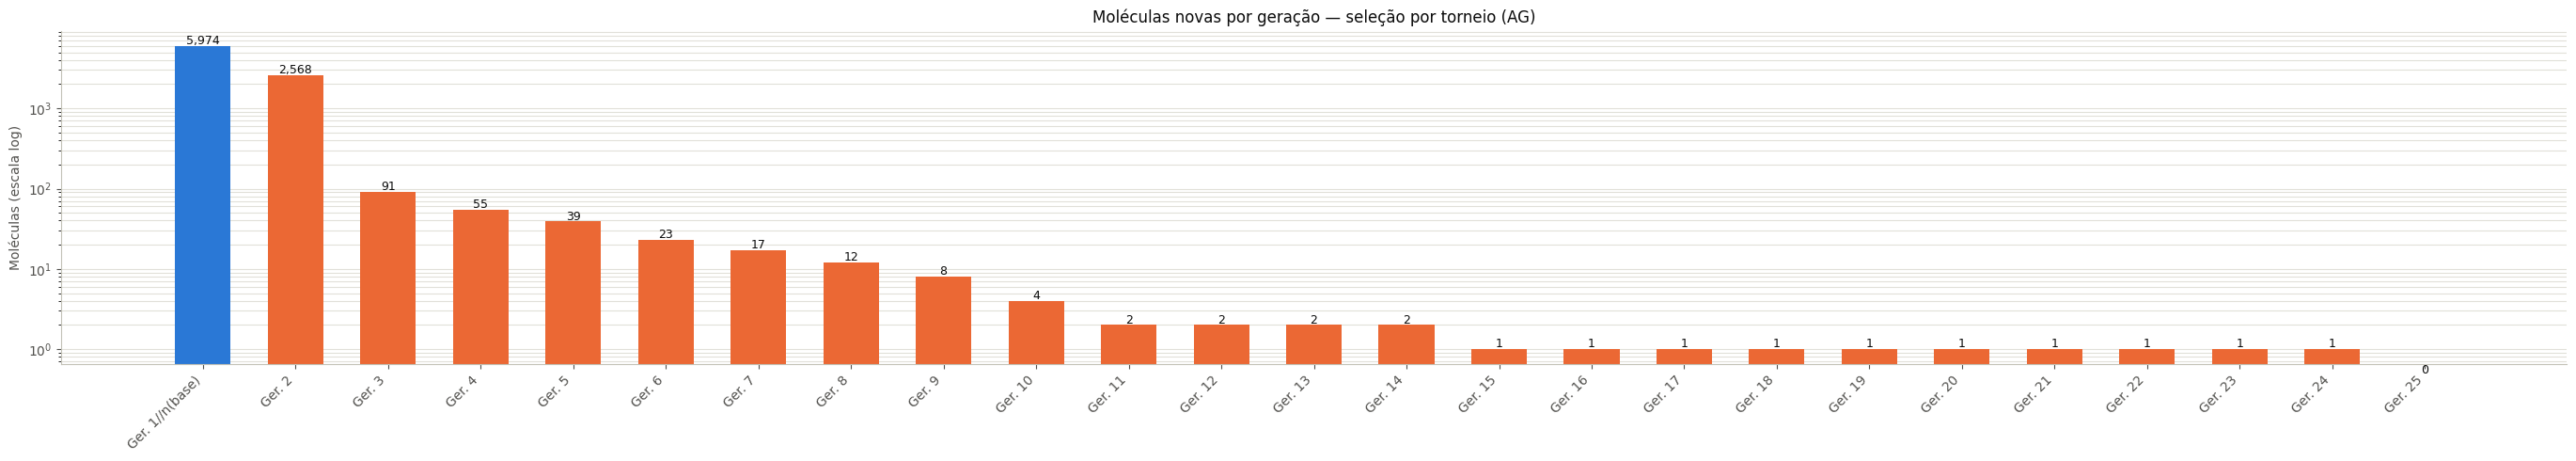

In [44]:
PALETA = {
    'azul':     '#2a78d6',
    'laranja':  '#eb6834',
    'verde':    '#2aad6a',
    'grade':    '#e1e0d9',
    'eixo':     '#c3c2b7',
    'primario': '#0b0b0b',
    'secund':   '#52514e',
}


def estilizar(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color(PALETA['eixo'])
    ax.spines['bottom'].set_color(PALETA['eixo'])
    ax.tick_params(colors=PALETA['secund'])
    ax.xaxis.label.set_color(PALETA['secund'])
    ax.yaxis.label.set_color(PALETA['secund'])
    ax.title.set_color(PALETA['primario'])


# ── 1. Moléculas novas por geração ───────────────────────────────────────────
cats  = ['Ger. 1//n(base)'] + [f'Ger. {g}' for g in df_met['geracao']]
vals  = [n_base] + list(df_met['moleculas_novas'])
cores = [PALETA['azul']] + [PALETA['laranja']] * len(df_met)

fig, ax = plt.subplots(figsize=(max(6, 1.1 * len(cats)), 5))
barras = ax.bar(cats, vals, color=cores, width=0.6)
for bar, v in zip(barras, vals):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() * 1.05 if bar.get_height() > 0 else 0.5,
            f'{v:,}', ha='center', fontsize=9, color=PALETA['primario'])
ax.set_yscale('log')
ax.set_ylabel('Moléculas (escala log)')
ax.set_title('Moléculas novas por geração — seleção por torneio (AG)')
ax.grid(axis='y', color=PALETA['grade'], linewidth=0.8, which='both')
ax.set_axisbelow(True)
estilizar(ax)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

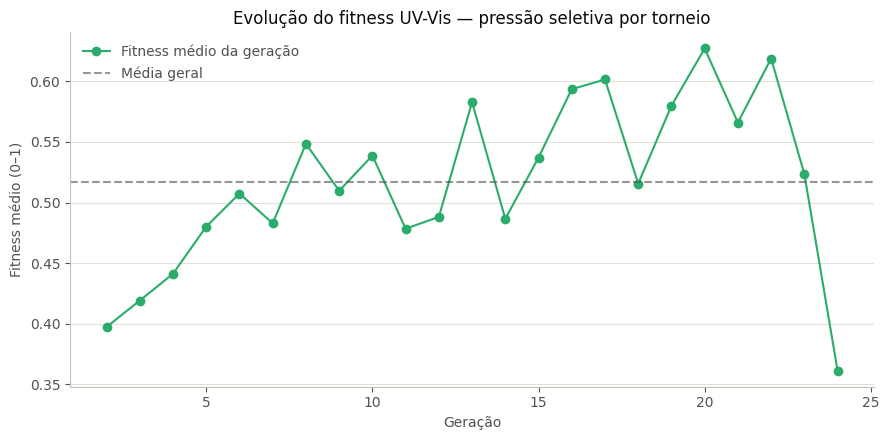

In [45]:
# ── 2. Evolução do fitness médio por geração ──────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df_met['geracao'], df_met['fitness_medio_geracao'],
        marker='o', color=PALETA['verde'], label='Fitness médio da geração')
ax.axhline(df_met['fitness_medio_geracao'].mean(),
           linestyle='--', color=PALETA['secund'], alpha=0.6, label='Média geral')
ax.set_xlabel('Geração')
ax.set_ylabel('Fitness médio (0–1)')
ax.set_title('Evolução do fitness UV-Vis — pressão seletiva por torneio')
ax.legend(frameon=False, labelcolor=PALETA['secund'])
ax.grid(axis='y', color=PALETA['grade'], linewidth=0.8)
ax.set_axisbelow(True)
estilizar(ax)
plt.tight_layout()
plt.show()

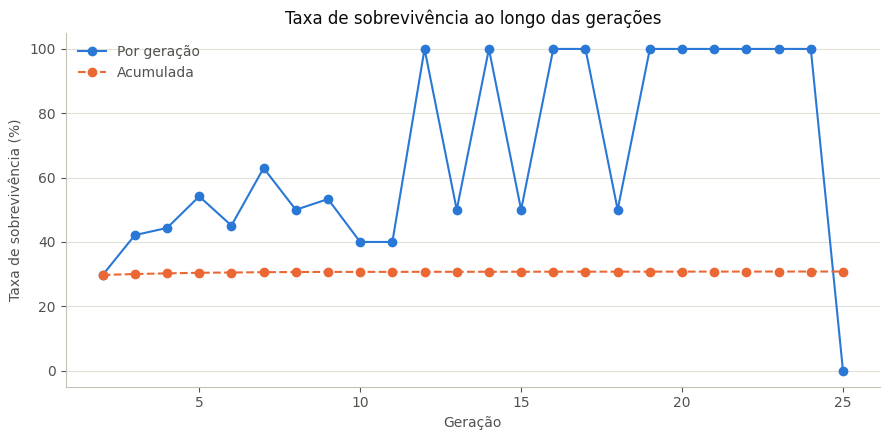

In [46]:
# ── 3. Taxa de sobrevivência por geração ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df_met['geracao'], df_met['taxa_sobrevivencia'] * 100,
        marker='o', color=PALETA['azul'], label='Por geração')
ax.plot(df_met['geracao'], df_met['taxa_sobrevivencia_acum'] * 100,
        marker='o', linestyle='--', color=PALETA['laranja'], label='Acumulada')
ax.set_xlabel('Geração')
ax.set_ylabel('Taxa de sobrevivência (%)')
ax.set_title('Taxa de sobrevivência ao longo das gerações')
ax.legend(frameon=False, labelcolor=PALETA['secund'])
ax.grid(axis='y', color=PALETA['grade'], linewidth=0.8)
ax.set_axisbelow(True)
estilizar(ax)
plt.tight_layout()
plt.show()

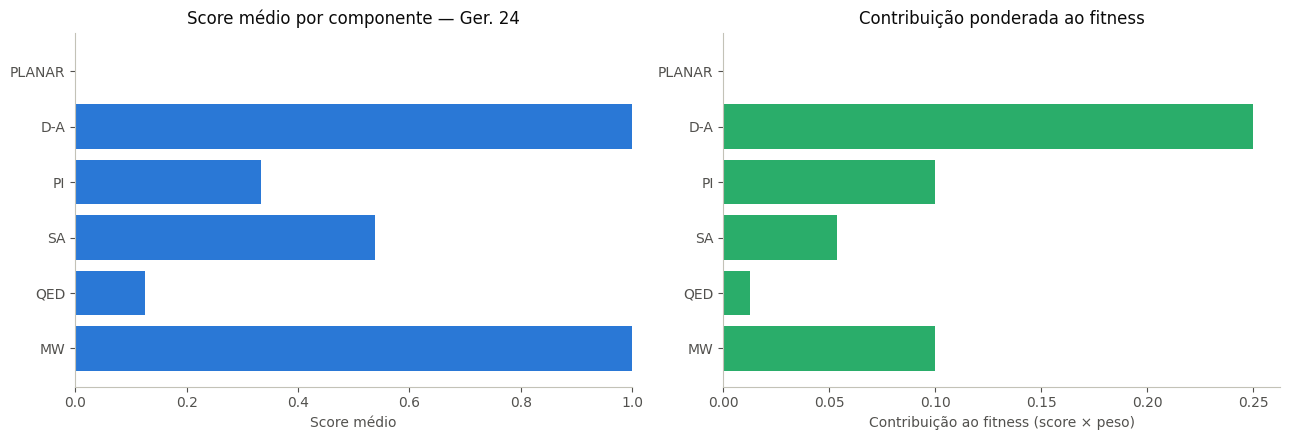

//nFitness médio na Ger. 24: 0.3614
PAINS detectados:               1 / 1


In [47]:
# ── 4. Decomposição do fitness — última geração bem-sucedida ──────────────────
ult_num = df_met.loc[df_met['moleculas_novas'] > 0, 'geracao'].iloc[-1]  if (df_met['moleculas_novas'] > 0).any() else None

if ult_num is not None and ult_num in historico_por_geracao:
    df_ult = historico_por_geracao[ult_num]
    cols_score = ['mw_score', 'qed_score', 'sa_score', 'pi_score', 'd_a_score', 'planar_score']
    cols_pres  = [c for c in cols_score if c in df_ult.columns]

    if cols_pres:
        medias  = df_ult[cols_pres].mean()
        rotulos = [c.replace('_score', '').replace('_', '-').upper() for c in cols_pres]
        pesos_d = {'mw_score': 0.10, 'qed_score': 0.10, 'sa_score': 0.10,
                   'pi_score': 0.30, 'd_a_score': 0.25, 'planar_score': 0.15}
        contrib = [medias[c] * pesos_d.get(c, 0) for c in cols_pres]

        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

        axes[0].barh(rotulos, medias[cols_pres].values, color=PALETA['azul'])
        axes[0].set_xlim(0, 1)
        axes[0].set_xlabel('Score médio')
        axes[0].set_title(f'Score médio por componente — Ger. {ult_num}')
        estilizar(axes[0])

        axes[1].barh(rotulos, contrib, color=PALETA['verde'])
        axes[1].set_xlabel('Contribuição ao fitness (score × peso)')
        axes[1].set_title('Contribuição ponderada ao fitness')
        estilizar(axes[1])

        plt.tight_layout()
        plt.show()

        print(f'//nFitness médio na Ger. {ult_num}: {df_ult["fitness"].mean():.4f}')
        print(f'PAINS detectados:               {df_ult["tem_pains"].sum()} / {len(df_ult)}')

## 14. Comparação de configurações de pesos

Seis filosofias de ponderação, com hipóteses distintas sobre o que mais importa para um corante UV-Vis.
A melhor configuração é avaliada por **métricas estruturais independentes dos pesos** — proxies objetivos
para qualidade UV-Vis — aplicadas sobre o top-10% selecionado por cada config.

| Config | Hipótese central |
|---|---|
| `base` | Equilíbrio entre UV-Vis e sintetizabilidade (config original) |
| `uvvis_puro` | Maximiza conjugação e push-pull; quase ignora farmacoquímica |
| `sintetizavel` | Prioriza QED + SA score; UV-Vis em segundo plano |
| `uniforme` | Sem hipótese — todos os componentes valem igual |
| `planaridade` | Enfatiza planaridade junto com conjugação |
| `farmaco_like` | Filosofia de drug discovery; MW + QED + SA dominam |

In [48]:
# ── 14.1 Definição das configurações e função de recálculo ───────────────────
CONFIGS_PESOS = {
    'base':         {'mw': 0.10, 'qed': 0.10, 'sa': 0.10, 'pi': 0.30, 'd_a': 0.25, 'planar': 0.15},
    'uvvis_puro':   {'mw': 0.05, 'qed': 0.05, 'sa': 0.05, 'pi': 0.40, 'd_a': 0.35, 'planar': 0.10},
    'sintetizavel': {'mw': 0.15, 'qed': 0.20, 'sa': 0.20, 'pi': 0.20, 'd_a': 0.15, 'planar': 0.10},
    'uniforme':     {'mw': 1/6,  'qed': 1/6,  'sa': 1/6,  'pi': 1/6,  'd_a': 1/6,  'planar': 1/6 },
    'planaridade':  {'mw': 0.05, 'qed': 0.05, 'sa': 0.10, 'pi': 0.30, 'd_a': 0.20, 'planar': 0.30},
    'farmaco_like': {'mw': 0.20, 'qed': 0.25, 'sa': 0.20, 'pi': 0.15, 'd_a': 0.10, 'planar': 0.10},
}

for nome, p in CONFIGS_PESOS.items():
    s = sum(p.values())
    assert abs(s - 1.0) < 1e-9, f'{nome}: pesos somam {s:.6f}'

print('Configurações (linhas = componente, colunas = config):')
display(pd.DataFrame(CONFIGS_PESOS).T.round(4))


def recalcular_fitness(df: pd.DataFrame, pesos: dict, pains_fator: float = 1.0) -> pd.Series:
    """Recalcula fitness usando scores parciais já presentes no df."""
    cols_req = ['mw_score', 'qed_score', 'sa_score', 'pi_score', 'd_a_score', 'planar_score', 'tem_pains']
    faltando = [c for c in cols_req if c not in df.columns]
    if faltando:
        raise ValueError(f'Colunas ausentes no df: {faltando}')
    fator = df['tem_pains'].map({True: pains_fator, False: 1.0}).fillna(1.0)
    return (
        pesos['mw']     * df['mw_score']     +
        pesos['qed']    * df['qed_score']    +
        pesos['sa']     * df['sa_score']     +
        pesos['pi']     * df['pi_score']     +
        pesos['d_a']    * df['d_a_score']    +
        pesos['planar'] * df['planar_score']
    ) * fator


print('\nFunção recalcular_fitness definida.')

Configurações (linhas = componente, colunas = config):


,mw,qed,sa,pi,d_a,planar
base,0.1000,0.1000,0.1000,0.3000,0.2500,0.1500
uvvis_puro,0.0500,0.0500,0.0500,0.4000,0.3500,0.1000
sintetizavel,0.1500,0.2000,0.2000,0.2000,0.1500,0.1000
uniforme,0.1667,0.1667,0.1667,0.1667,0.1667,0.1667
planaridade,0.0500,0.0500,0.1000,0.3000,0.2000,0.3000
farmaco_like,0.2000,0.2500,0.2000,0.1500,0.1000,0.1000



Função recalcular_fitness definida.


In [49]:
# ── 14.2 Pool de avaliação + recálculo de fitness por config ─────────────────
_cols_pool = [
    'mw_score', 'qed_score', 'sa_score', 'pi_score', 'd_a_score', 'planar_score',
    'tem_pains', 'mw', 'sa', 'n_aneis_aromaticos', 'n_doadores', 'n_aceptores',
    'n_cromoforos', 'smiles',
]

_frames = []
for num, df_g in historico_por_geracao.items():
    if num == 1:
        continue
    if 'mw_score' not in df_g.columns:
        continue
    sub = df_g[[c for c in _cols_pool if c in df_g.columns]].copy()
    sub['geracao'] = num
    _frames.append(sub)

df_pool = pd.concat(_frames, ignore_index=True) if _frames else pd.DataFrame()
print(f'Pool de avaliação: {len(df_pool):,} moléculas (gerações 2–{max(historico_por_geracao)})')

# Recalcula fitness para cada configuração (não reparseia SMILES — usa scores já salvos)
for nome, pesos in CONFIGS_PESOS.items():
    df_pool[f'fit_{nome}'] = recalcular_fitness(df_pool, pesos)

resumo_fit = pd.DataFrame({
    nome: {
        'fitness médio':  df_pool[f'fit_{nome}'].mean(),
        'desvio padrão':  df_pool[f'fit_{nome}'].std(),
        'top-10% corte':  df_pool[f'fit_{nome}'].quantile(0.90),
        'máximo':         df_pool[f'fit_{nome}'].max(),
    }
    for nome in CONFIGS_PESOS
}).T.round(4)

print('\nFitness médio por configuração:')
display(resumo_fit)

Pool de avaliação: 2,835 moléculas (gerações 2–24)

Fitness médio por configuração:


,fitness médio,desvio padrão,top-10% corte,máximo
base,0.4035,0.0850,0.5204,0.7891
uvvis_puro,0.4113,0.0918,0.5626,0.8082
sintetizavel,0.4144,0.0840,0.5215,0.7365
uniforme,0.4288,0.0843,0.5340,0.7700
planaridade,0.3249,0.0863,0.4390,0.7993
farmaco_like,0.4245,0.0855,0.5299,0.7286


In [50]:
# ── 14.3 Métricas de avaliação independentes dos pesos ───────────────────────
# Critérios estruturais objetivos — não dependem de nenhuma configuração de pesos.
# "Candidato forte" = molécula que satisfaz simultaneamente os 4 critérios UV-Vis essenciais.

def metricas_independentes(df: pd.DataFrame) -> dict:
    cond_d_pi_a = (df['n_doadores'] >= 1) & (df['n_aceptores'] >= 1)
    cond_forte  = (
        (df['n_aneis_aromaticos'] >= 2) &
        cond_d_pi_a &
        df['mw'].between(200, 700) &
        (df['sa'] <= 5)
    )
    return {
        '≥2 anéis arom.':    round((df['n_aneis_aromaticos'] >= 2).mean() * 100, 1),
        'D-π-A completo':    round(cond_d_pi_a.mean()  * 100, 1),
        'cromóforo presente':round((df['n_cromoforos'] >= 1).mean() * 100, 1),
        'MW 200–700 Da':     round(df['mw'].between(200, 700).mean() * 100, 1),
        'SA ≤ 5':            round((df['sa'] <= 5).mean() * 100, 1),
        'sem PAINS':         round((~df['tem_pains']).mean() * 100, 1),
        'candidato forte':   round(cond_forte.mean() * 100, 1),
    }


# Referência: métricas do pool inteiro
met_pool = metricas_independentes(df_pool)
print('Métricas do pool inteiro (linha de base):')
for k, v in met_pool.items():
    print(f'  {k:<24} {v:5.1f}%')

# Métricas do top-10% selecionado por cada config
from scipy.stats import spearmanr

cond_forte_bin = (
    (df_pool['n_aneis_aromaticos'] >= 2) &
    ((df_pool['n_doadores'] >= 1) & (df_pool['n_aceptores'] >= 1)) &
    df_pool['mw'].between(200, 700) &
    (df_pool['sa'] <= 5)
).astype(int)

linhas_corr = []
n_top = max(1, int(len(df_pool) * 0.10))

for nome in CONFIGS_PESOS:
    col = f'fit_{nome}'
    r, p = spearmanr(df_pool[col], cond_forte_bin)
    top_idx = df_pool[col].nlargest(n_top).index
    met_top = metricas_independentes(df_pool.loc[top_idx])
    linhas_corr.append({
        'config':         nome,
        'ρ Spearman':     round(r, 4),
        **{k + ' (%)': v for k, v in met_top.items()},
    })

df_comp = (
    pd.DataFrame(linhas_corr)
    .set_index('config')
    .sort_values('candidato forte (%)', ascending=False)
)
print(f'\nQualidade do top-{n_top} ({100*n_top/len(df_pool):.0f}%) por cada configuração:')
display(df_comp)

Métricas do pool inteiro (linha de base):
  ≥2 anéis arom.             0.7%
  D-π-A completo            95.5%
  cromóforo presente        79.2%
  MW 200–700 Da             98.0%
  SA ≤ 5                    10.2%
  sem PAINS                 72.5%
  candidato forte            0.6%

Qualidade do top-283 (10%) por cada configuração:


,ρ Spearman,≥2 anéis arom. (%),D-π-A completo (%),cromóforo presente (%),MW 200–700 Da (%),SA ≤ 5 (%),sem PAINS (%),candidato forte (%)
config,,,,,,,,
base,0.1074,4.9,97.9,90.5,100.0,51.2,100.0,4.6
uvvis_puro,0.1145,4.6,100.0,97.9,100.0,47.3,100.0,4.6
sintetizavel,0.0981,5.3,94.3,78.4,100.0,51.6,100.0,4.6
planaridade,0.1096,4.9,94.7,77.0,100.0,33.6,99.3,4.6
uniforme,0.0835,4.6,94.3,81.3,100.0,41.3,100.0,4.2
farmaco_like,0.0877,4.9,91.5,72.4,100.0,47.7,100.0,4.2


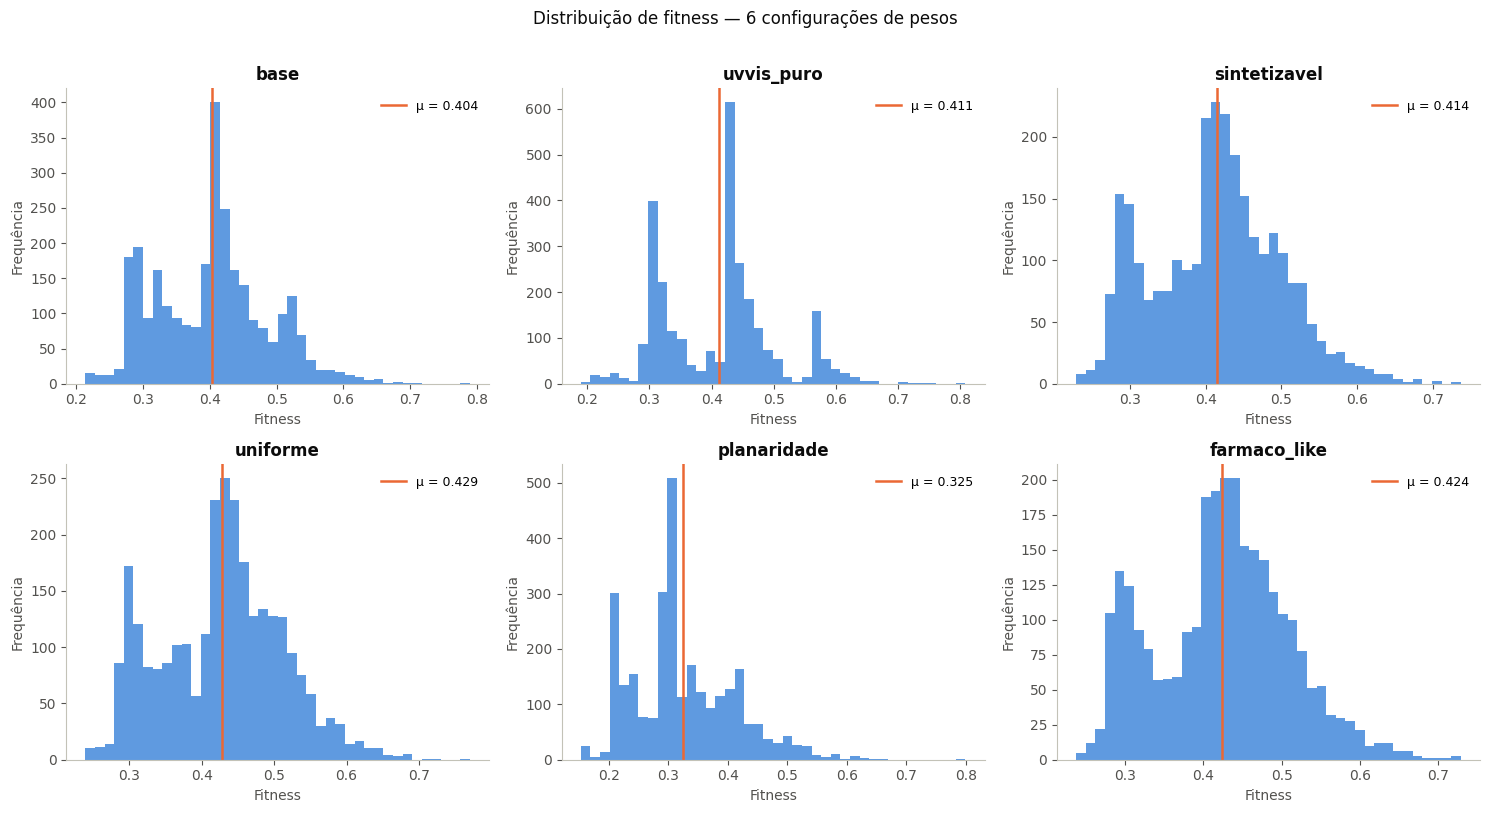

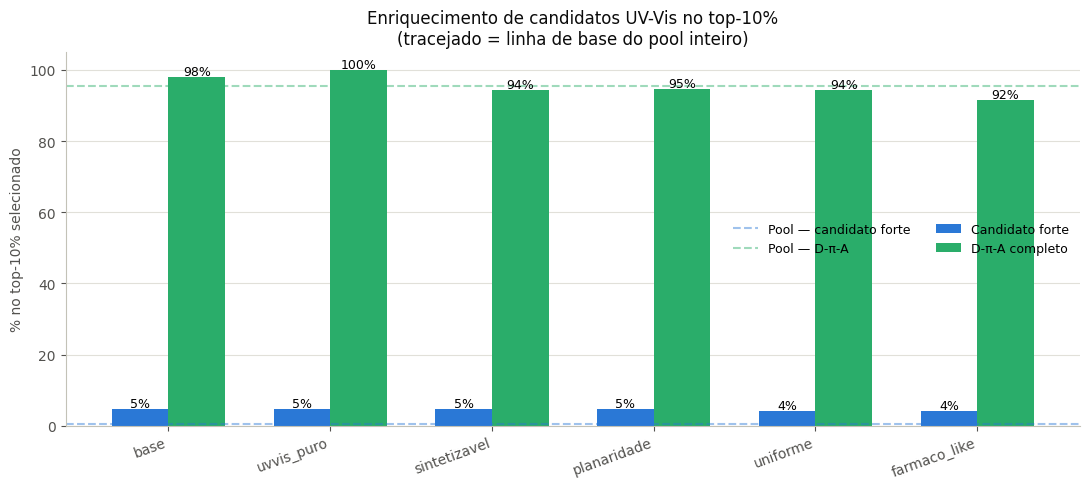

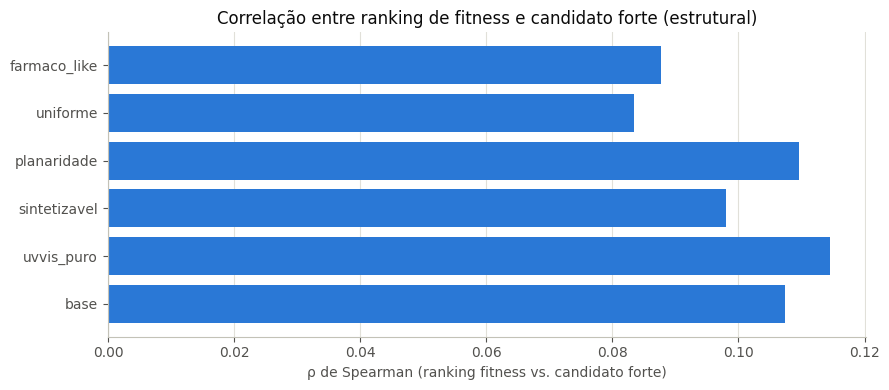

────────────────────────────────────────────────────────────
Maior % de candidatos fortes no top-10%:
  → base  (4.6%)
Maior correlação Spearman com candidato forte:
  → uvvis_puro  (ρ = 0.1145)
────────────────────────────────────────────────────────────


In [51]:
# ── 14.4 Visualizações comparativas ──────────────────────────────────────────

# Gráfico 1: distribuição de fitness por configuração
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
for ax, nome in zip(axes.flatten(), CONFIGS_PESOS):
    col = f'fit_{nome}'
    ax.hist(df_pool[col], bins=40, color=PALETA['azul'], alpha=0.75, edgecolor='none')
    ax.axvline(df_pool[col].mean(), color=PALETA['laranja'], linewidth=1.8,
               label=f'μ = {df_pool[col].mean():.3f}')
    ax.set_title(nome, fontweight='bold')
    ax.set_xlabel('Fitness')
    ax.set_ylabel('Frequência')
    ax.legend(frameon=False, fontsize=9)
    estilizar(ax)
plt.suptitle('Distribuição de fitness — 6 configurações de pesos', y=1.01, color=PALETA['primario'])
plt.tight_layout()
plt.show()

# Gráfico 2: qualidade do top-10% por config (candidato forte + D-π-A)
configs_ord   = df_comp.index.tolist()
vals_forte    = df_comp['candidato forte (%)'].values
vals_d_pi_a   = df_comp['D-π-A completo (%)'].values
x = np.arange(len(configs_ord))
w = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
bars1 = ax.bar(x - w/2, vals_forte,  w, color=PALETA['azul'],  label='Candidato forte')
bars2 = ax.bar(x + w/2, vals_d_pi_a, w, color=PALETA['verde'], label='D-π-A completo')
for bar, v in zip(bars1, vals_forte):
    ax.text(bar.get_x() + w/2, bar.get_height() + 0.6, f'{v:.0f}%', ha='center', fontsize=9)
for bar, v in zip(bars2, vals_d_pi_a):
    ax.text(bar.get_x() + w/2, bar.get_height() + 0.6, f'{v:.0f}%', ha='center', fontsize=9)
ax.axhline(met_pool['candidato forte'],  linestyle='--', color=PALETA['azul'],  alpha=0.45, label='Pool — candidato forte')
ax.axhline(met_pool['D-π-A completo'],   linestyle='--', color=PALETA['verde'], alpha=0.45, label='Pool — D-π-A')
ax.set_xticks(x)
ax.set_xticklabels(configs_ord, rotation=20, ha='right')
ax.set_ylabel('% no top-10% selecionado')
ax.set_title('Enriquecimento de candidatos UV-Vis no top-10%\n(tracejado = linha de base do pool inteiro)')
ax.legend(frameon=False, fontsize=9, ncol=2)
ax.grid(axis='y', color=PALETA['grade'], linewidth=0.8)
ax.set_axisbelow(True)
estilizar(ax)
plt.tight_layout()
plt.show()

# Gráfico 3: correlação de Spearman (ranking vs. candidato forte)
fig, ax = plt.subplots(figsize=(9, 4))
cores_rho = [PALETA['azul'] if v >= 0 else PALETA['laranja'] for v in df_comp['ρ Spearman']]
ax.barh(df_comp.index, df_comp['ρ Spearman'], color=cores_rho)
ax.axvline(0, color=PALETA['eixo'])
ax.set_xlabel('ρ de Spearman (ranking fitness vs. candidato forte)')
ax.set_title('Correlação entre ranking de fitness e candidato forte (estrutural)')
ax.grid(axis='x', color=PALETA['grade'], linewidth=0.8)
ax.set_axisbelow(True)
estilizar(ax)
plt.tight_layout()
plt.show()

# Resumo textual
melhor_forte = df_comp['candidato forte (%)'].idxmax()
melhor_rho   = df_comp['ρ Spearman'].idxmax()
print('─' * 60)
print(f'Maior % de candidatos fortes no top-10%:')
print(f'  → {melhor_forte}  ({df_comp.loc[melhor_forte, "candidato forte (%)"]:.1f}%)')
print(f'Maior correlação Spearman com candidato forte:')
print(f'  → {melhor_rho}  (ρ = {df_comp.loc[melhor_rho, "ρ Spearman"]:.4f})')
print('─' * 60)

## 15. Loop multi-configuração + Avaliação por Estágio 3 (Liu & Liu, IJMS 2026)

Para cada configuração de pesos de fitness definida na Seção 14, executa um mini-loop
evolutivo **independente** (parâmetros reduzidos para agilidade) e avalia os conjuntos
gerados usando métricas de **Estágio 3** do framework de Liu & Liu (IJMS 27:5916, 2026):

| Métrica (Estágio 3) | Definição |
|---|---|
| **Novelty exata** | Fração das moléculas geradas ausentes na base de referência |
| **IntDiv1** | 1 − Tanimoto médio entre pares (fingerprint Morgan 2048 bits) |
| **Scaffold Novelty** | Fração dos scaffolds Bemis–Murcko não presentes na base |
| **Scaffold Uniqueness** | Scaffolds únicos / total de moléculas geradas |

Essas métricas são **independentes dos pesos** escolhidos para o fitness, sendo
proxies estruturais objetivos para diversidade e novidade química das moléculas
produzidas sob cada pressão seletiva.

In [52]:
# ── Estágio 3: funções de avaliação de novidade e diversidade ────────────────
from rdkit.Chem import AllChem, DataStructs
from rdkit.Chem.Scaffolds import MurckoScaffold


def morgan_fps(smiles_iter, radius=2, n_bits=2048):
    fps = []
    for smi in smiles_iter:
        mol = Chem.MolFromSmiles(str(smi))
        if mol is not None:
            fps.append(AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits))
    return fps


def intdiv1(fps, n_amostra=500, rng_seed=42):
    """
    IntDiv1 — Stage 3, Liu & Liu (IJMS 2026):
    1 − média de similaridade Tanimoto sobre pares (subsample para eficiência).
    Valores próximos de 1 indicam alta diversidade interna.
    """
    rng = random.Random(rng_seed)
    n = len(fps)
    if n < 2:
        return float('nan')
    idx = list(range(n))
    if n > n_amostra:
        idx = rng.sample(idx, n_amostra)
    total_sim, n_pares = 0.0, 0
    for i in range(len(idx)):
        parceiros = [fps[idx[j]] for j in range(i + 1, len(idx))]
        if parceiros:
            sims = DataStructs.BulkTanimotoSimilarity(fps[idx[i]], parceiros)
            total_sim += sum(sims)
            n_pares += len(sims)
    return round(1.0 - total_sim / n_pares, 4) if n_pares > 0 else float('nan')


def _scaffold(smi):
    mol = Chem.MolFromSmiles(str(smi))
    if mol is None:
        return None
    try:
        return Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(mol))
    except Exception:
        return None


def scaffold_novelty(smiles_geradas, scaffolds_base_set):
    """
    Scaffold Novelty — Stage 3:
    Fração dos scaffolds Bemis–Murcko das moléculas geradas
    ausentes na base de referência (maior = mais novidade estrutural).
    """
    n_novas = n_total = 0
    for smi in smiles_geradas:
        s = _scaffold(smi)
        if s is not None:
            n_total += 1
            if s not in scaffolds_base_set:
                n_novas += 1
    return round(n_novas / n_total, 4) if n_total > 0 else 0.0


def scaffold_uniqueness(smiles_list):
    """
    Scaffold Uniqueness — Stage 3:
    Razão scaffolds únicos / total de moléculas (maior = mais diversidade).
    """
    scaffolds = [_scaffold(s) for s in smiles_list]
    scaffolds = [s for s in scaffolds if s is not None]
    if not scaffolds:
        return 0.0
    return round(len(set(scaffolds)) / len(scaffolds), 4)


# Pré-computa scaffolds da base de referência (uma vez)
print('Calculando scaffolds da base de referência...', end=' ')
_scaffolds_base = set()
for smi in df_base['smiles'].dropna():
    s = _scaffold(smi)
    if s:
        _scaffolds_base.add(s)
print(f'{len(_scaffolds_base):,} scaffolds únicos na base.')
print('Funções de Estágio 3 definidas.')

Calculando scaffolds da base de referência... 

[08:35:35] Can't kekulize mol.  Unkekulized atoms: 5 6 29 30 34
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 3 4 18 19 22
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 18 19 20 22 23
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 4 5 9 10 13
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 3 4 8 9 30
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 10 11 14 16 21
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 23 24 29 32
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 24 25 27 29
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 5 6 11 14 15
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 6 9 10 13
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 11 12 13 20 21
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 26
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 7 8 9
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 12 13 16 17 18
[08:35:35] Can't kekulize mol.  Unkekulized atoms: 5 6 9 14 15
[08:35:35] Can't kekulize mol.  Unkekulized atoms:

2,450 scaffolds únicos na base.
Funções de Estágio 3 definidas.


[08:35:37] Can't kekulize mol.  Unkekulized atoms: 5 6 30
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 15 16 17 26 27
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 13 14 15 20 25
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 4 8 14
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 5 9 10
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 3 4 20 21 23
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 5 6 30 31 33
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 4 5 7 9 21
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 13 15 21 22 24
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 1 2 3 5 16
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 19 20 21 24
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 12 13 15 17 19
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 2 3 6 38
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 5 6 11 12 33
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 3 5 30
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 5 6 7 9 12
[08

In [53]:
# ── Parâmetros do mini-loop (reduzidos para agilidade) ───────────────────────
MAX_GERACOES_MINI   = 10   # teto por configuração
N_SONDAS_MINI       = 5    # sondas TED por semente
N_SEMENTES_MINI     = 50   # sementes por torneio no mini-loop
N_SEMENTES_INICIAL  = 300  # moléculas da base usadas como seed inicial
K_TORNEIO_MINI      = 5    # ablacao C

df_base_mini = df_base.sample(N_SEMENTES_INICIAL, random_state=42).reset_index(drop=True)

# Canonicos iniciais compartilhados por todos os mini-runs
_can_c_base_mini = set(df_base_mini['SMILES_Canonico_Complexo'].dropna())
_can_a_base_mini = set()
for smi in df_base_mini['smiles'].dropna():
    mol = Chem.MolFromSmiles(str(smi))
    if mol:
        _can_a_base_mini.add(Chem.MolToSmiles(mol))

# ── Mini-loop por configuração de pesos ─────────────────────────────────────
resultados_mini = {}   # nome_cfg -> DataFrame com todas as moléculas geradas
estatisticas_mini = {} # nome_cfg -> lista de dicts de estatísticas por geração

for nome_cfg, pesos_cfg in CONFIGS_PESOS.items():
    hist_mini        = df_base_mini.copy()
    can_c_mini       = set(_can_c_base_mini)
    can_a_mini       = set(_can_a_base_mini)
    df_seeds_mini    = df_base_mini.copy()
    comb_inv_mini    = set()
    rng_mini         = random.Random(42)
    todas_geradas    = []
    estats_cfg       = []

    for g in range(1, MAX_GERACOES_MINI + 1):
        df_nova, estat = rodar_uma_geracao(
            df_seeds_mini, hist_mini, catalogo_pontes_lista,
            can_c_mini, can_a_mini,
            numero_geracao=g,
            n_sondas=N_SONDAS_MINI,
            semente=42 + g,
            combinacoes_invalidas_conhecidas=comb_inv_mini,
        )
        if len(df_nova) == 0:
            break

        # Recalcula fitness com os pesos DESTA configuração
        if 'mw_score' in df_nova.columns:
            df_nova['fitness'] = recalcular_fitness(df_nova, pesos_cfg)

        estat['config'] = nome_cfg
        estats_cfg.append(estat)
        todas_geradas.append(df_nova)

        can_c_mini |= set(df_nova['SMILES_Canonico_Complexo_Candidato'].dropna())
        can_a_mini |= set(df_nova['smiles'].dropna())
        df_nova_ren = df_nova.rename(columns=MAPA_COLUNAS)
        hist_mini = pd.concat([hist_mini, df_nova_ren], ignore_index=True)

        n_sel = min(N_SEMENTES_MINI, len(df_nova))
        df_seeds_mini = selecionar_sementes_torneio(
            df_nova_ren, n_sel, 'fitness', K_TORNEIO_MINI, rng_mini)

    df_run = pd.concat(todas_geradas, ignore_index=True) if todas_geradas else pd.DataFrame(columns=['smiles', 'fitness'])
    resultados_mini[nome_cfg]   = df_run
    estatisticas_mini[nome_cfg] = estats_cfg
    print(f'  {nome_cfg:15s}: {len(df_run):4,} moléculas em {len(estats_cfg)} gerações'
          f'   fitness médio = {df_run["fitness"].mean():.4f}' if not df_run.empty else f'  {nome_cfg}: 0 moléculas')

print('\nMini-loops concluídos.')

[08:35:37] Can't kekulize mol.  Unkekulized atoms: 2 3 4 7
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 12 13 16 22 23
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 18 19 24 25 26
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 2 4 5 9
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 10 12 15 17
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 4 5 22
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 3 5 6 20 23
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 5 6 7 14 31
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 16 17 18 23 30
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 26 27 37
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 3 4 5 9 33
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 6 7 8 30
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 5 6 7 23 26
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 5 6 7 13 18
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 2 3 4 34 35
[08:35:37] Can't kekulize mol.  Unkekulized atoms: 15 16 23 24 26


  base           :  235 moléculas em 8 gerações   fitness médio = 0.4048


[08:35:44] Explicit valence for atom # 10 N, 4, is greater than permitted
[08:35:44] Explicit valence for atom # 10 O, 4, is greater than permitted
[08:35:44] Explicit valence for atom # 11 C, 5, is greater than permitted
[08:35:44] Explicit valence for atom # 20 O, 3, is greater than permitted
[08:35:44] Explicit valence for atom # 18 N, 4, is greater than permitted
[08:35:44] Explicit valence for atom # 22 B, 4, is greater than permitted
[08:35:44] Explicit valence for atom # 10 O, 3, is greater than permitted
[08:35:44] Explicit valence for atom # 19 B, 4, is greater than permitted
[08:35:44] Explicit valence for atom # 20 N, 5, is greater than permitted
[08:35:44] Can't kekulize mol.  Unkekulized atoms: 32 35 38
[08:35:44] Explicit valence for atom # 15 O, 3, is greater than permitted
[08:35:44] Explicit valence for atom # 17 N, 4, is greater than permitted
[08:35:44] Explicit valence for atom # 18 O, 3, is greater than permitted
[08:35:44] Explicit valence for atom # 16 N, 4, is g

  uvvis_puro     :  235 moléculas em 8 gerações   fitness médio = 0.4114


[08:35:51] Explicit valence for atom # 17 N, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 18 O, 3, is greater than permitted
[08:35:51] Explicit valence for atom # 16 N, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 18 N, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 13 C, 5, is greater than permitted
[08:35:51] Explicit valence for atom # 14 N, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 18 N, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 14 N, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 14 N, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 13 N, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 16 O, 4, is greater than permitted
[08:35:51] Explicit valence for atom # 16 O, 3, is greater than permitted
[08:35:51] Explicit valence for atom # 16 O, 3, is greater than permitted
[08:35:51] Explicit valence for atom #

  sintetizavel   :  233 moléculas em 8 gerações   fitness médio = 0.4235


... (3 outputs left out)

  planaridade    :  242 moléculas em 10 gerações   fitness médio = 0.3221


[08:36:09] Explicit valence for atom # 20 N, 5, is greater than permitted
[08:36:09] Can't kekulize mol.  Unkekulized atoms: 32 35 38
[08:36:09] Explicit valence for atom # 15 O, 3, is greater than permitted
[08:36:09] Explicit valence for atom # 17 N, 4, is greater than permitted
[08:36:09] Explicit valence for atom # 18 O, 3, is greater than permitted
[08:36:09] Explicit valence for atom # 16 N, 4, is greater than permitted
[08:36:09] Explicit valence for atom # 18 N, 4, is greater than permitted
[08:36:09] Explicit valence for atom # 13 C, 5, is greater than permitted
[08:36:09] Explicit valence for atom # 14 N, 4, is greater than permitted
[08:36:09] Explicit valence for atom # 18 N, 4, is greater than permitted
[08:36:09] Explicit valence for atom # 14 N, 4, is greater than permitted
[08:36:09] Explicit valence for atom # 14 N, 4, is greater than permitted
[08:36:09] Explicit valence for atom # 13 N, 4, is greater than permitted
[08:36:09] Explicit valence for atom # 16 O, 4, is g

  farmaco_like   :  232 moléculas em 8 gerações   fitness médio = 0.4353

Mini-loops concluídos.


[08:36:15] Explicit valence for atom # 16 N, 4, is greater than permitted
[08:36:15] Explicit valence for atom # 19 O, 3, is greater than permitted
[08:36:15] Explicit valence for atom # 16 O, 3, is greater than permitted
[08:36:15] Can't kekulize mol.  Unkekulized atoms: 13 14 16 18
[08:36:15] Can't kekulize mol.  Unkekulized atoms: 2 3 4 21 22
[08:36:15] Can't kekulize mol.  Unkekulized atoms: 15 16 20 22 23
[08:36:15] Can't kekulize mol.  Unkekulized atoms: 2 4 9 28 29


In [54]:
# ── Cálculo das métricas de Estágio 3 para cada configuração ────────────────
linhas_eval = []

for nome_cfg, df_run in resultados_mini.items():
    if df_run.empty:
        linhas_eval.append({'config': nome_cfg})
        continue

    smiles_geradas = df_run['smiles'].dropna().tolist()

    # Novidade exata (Stage 3)
    n_novas = sum(1 for s in smiles_geradas if s not in _can_a_base_mini)
    novelty  = n_novas / len(smiles_geradas) if smiles_geradas else 0.0

    # IntDiv1 (Stage 3) — Morgan FP, Tanimoto
    fps_run = morgan_fps(smiles_geradas)
    div1    = intdiv1(fps_run)

    # Scaffold Novelty e Scaffold Uniqueness (Stage 3)
    scaf_nov = scaffold_novelty(smiles_geradas, _scaffolds_base)
    scaf_uniq = scaffold_uniqueness(smiles_geradas)

    # Métricas de Stage 2 (já calculadas, aproveitamos do df)
    cols_s2 = ['qed', 'sa', 'mw', 'tem_pains']
    qed_med = df_run['qed'].mean()      if 'qed'     in df_run.columns else float('nan')
    sa_med  = df_run['sa'].mean()       if 'sa'      in df_run.columns else float('nan')
    mw_med  = df_run['mw'].mean()       if 'mw'      in df_run.columns else float('nan')
    pains_p = df_run['tem_pains'].mean() if 'tem_pains' in df_run.columns else float('nan')
    fit_med = df_run['fitness'].mean()   if 'fitness' in df_run.columns else float('nan')

    # Lipinski RO5: MW<=500, logP<=5, HBD<=5, HBA<=10
    if 'mw' in df_run.columns and 'logp' in df_run.columns and 'hbd' in df_run.columns and 'hba' in df_run.columns:
        ro5 = (
            (df_run['mw']   <= 500) &
            (df_run['logp'] <=   5) &
            (df_run['hbd']  <=   5) &
            (df_run['hba']  <=  10)
        ).mean()
    else:
        ro5 = float('nan')

    linhas_eval.append({
        'config':            nome_cfg,
        'n_moleculas':       len(smiles_geradas),
        'fitness_medio':     round(fit_med,  4),
        # Stage 3 (Liu & Liu)
        'novelty_exata':     round(novelty,  4),
        'intdiv1':           div1,
        'scaffold_novelty':  scaf_nov,
        'scaffold_uniq':     scaf_uniq,
        # Stage 2 complementar
        'qed_medio':         round(qed_med,  3),
        'sa_medio':          round(sa_med,   3),
        'mw_medio':          round(mw_med,   1),
        'pct_sem_pains':     round(1 - pains_p, 3) if not np.isnan(pains_p) else float('nan'),
        'ro5_compliance':    round(ro5,      3),
    })
    print(f'  {nome_cfg:15s}: novelty={novelty:.3f} | IntDiv1={div1:.4f}'
          f' | scaf_nov={scaf_nov:.3f} | scaf_uniq={scaf_uniq:.3f}')

df_eval = pd.DataFrame(linhas_eval).set_index('config')

print('\n=== AVALIAÇÃO ESTÁGIO 3 (Liu & Liu, IJMS 2026) ===')
cols_s3 = ['n_moleculas', 'fitness_medio', 'novelty_exata', 'intdiv1', 'scaffold_novelty', 'scaffold_uniq']
display(df_eval[cols_s3].sort_values('intdiv1', ascending=False))

[08:36:15] DEPRECATION WARNING: please use MorganGenerator


[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerat

  base           : novelty=1.000 | IntDiv1=0.8742 | scaf_nov=0.889 | scaf_uniq=0.987


[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerator
[08:36:15] DEPRECATION WARNING: please use MorganGenerat

  uvvis_puro     : novelty=1.000 | IntDiv1=0.8737 | scaf_nov=0.889 | scaf_uniq=0.987


[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerator
[08:36:16] DEPRECATION WARNING: please use MorganGenerat

... (4 outputs left out)

  planaridade    : novelty=1.000 | IntDiv1=0.8709 | scaf_nov=0.897 | scaf_uniq=0.984


[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerator
[08:36:17] DEPRECATION WARNING: please use MorganGenerat

  farmaco_like   : novelty=1.000 | IntDiv1=0.8694 | scaf_nov=0.892 | scaf_uniq=0.991

=== AVALIAÇÃO ESTÁGIO 3 (Liu & Liu, IJMS 2026) ===


,n_moleculas,fitness_medio,novelty_exata,intdiv1,scaffold_novelty,scaffold_uniq
config,,,,,,
base,235,0.4048,1.0,0.8742,0.8894,0.9872
uvvis_puro,235,0.4114,1.0,0.8737,0.8894,0.9872
uniforme,227,0.4294,1.0,0.8730,0.8811,0.9912
planaridade,242,0.3221,1.0,0.8709,0.8967,0.9835
farmaco_like,232,0.4353,1.0,0.8694,0.8922,0.9914
sintetizavel,233,0.4235,1.0,0.8689,0.8927,0.9914


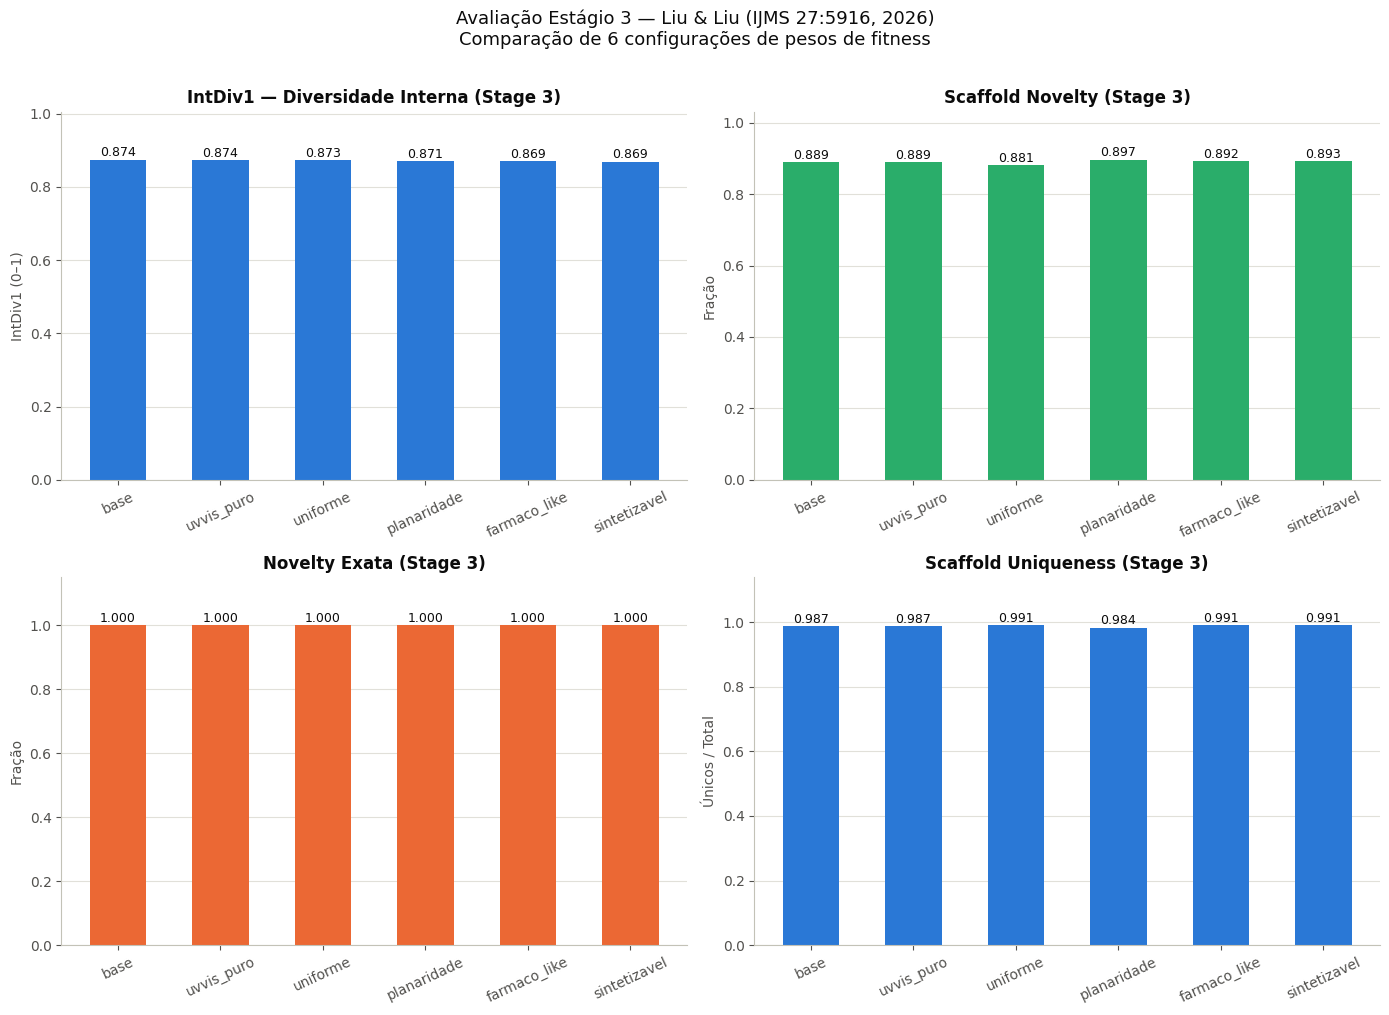

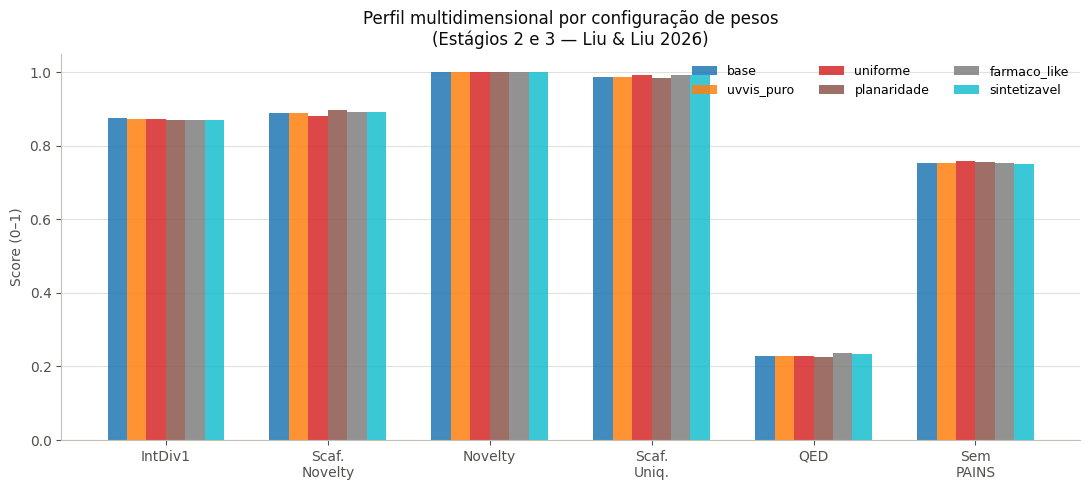

─────────────────────────────────────────────────────────────────
VENCEDOR POR CRITÉRIO (Estágio 3, Liu & Liu IJMS 2026)
  Maior diversidade interna  (IntDiv1):      base  (0.8742)
  Maior novidade de scaffold (Scaf. Nov.):   planaridade  (0.8967)
  Maior novelty exata:                       base  (1.0000)
─────────────────────────────────────────────────────────────────

Tabela completa (Stage 2 + Stage 3):


,n_moleculas,fitness_medio,novelty_exata,intdiv1,scaffold_novelty,scaffold_uniq,qed_medio,sa_medio,mw_medio,pct_sem_pains,ro5_compliance
config,,,,,,,,,,,
base,235,0.4048,1.0,0.8742,0.8894,0.9872,0.228,5.761,516.2,0.753,0.383
uvvis_puro,235,0.4114,1.0,0.8737,0.8894,0.9872,0.229,5.761,516.3,0.753,0.383
uniforme,227,0.4294,1.0,0.8730,0.8811,0.9912,0.228,5.842,512.4,0.758,0.388
planaridade,242,0.3221,1.0,0.8709,0.8967,0.9835,0.226,5.822,513.8,0.756,0.413
farmaco_like,232,0.4353,1.0,0.8694,0.8922,0.9914,0.236,5.712,515.0,0.754,0.379
sintetizavel,233,0.4235,1.0,0.8689,0.8927,0.9914,0.235,5.700,516.7,0.751,0.369


In [55]:
# ── Visualizações comparativas (Estágio 3) ───────────────────────────────────
configs_ord = df_eval['intdiv1'].sort_values(ascending=False).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

def bar_plot(ax, col, titulo, ylabel, cor):
    vals = [df_eval.loc[c, col] if c in df_eval.index else float('nan') for c in configs_ord]
    bars = ax.bar(configs_ord, vals, color=cor, width=0.55)
    for bar, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + max(vals) * 0.01,
                    f'{v:.3f}', ha='center', fontsize=9, color=PALETA['primario'])
    ax.set_title(titulo, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(v for v in vals if not np.isnan(v)) * 1.15 + 1e-6)
    ax.grid(axis='y', color=PALETA['grade'], linewidth=0.8)
    ax.set_axisbelow(True)
    estilizar(ax)
    ax.tick_params(axis='x', rotation=25)

bar_plot(axes[0, 0], 'intdiv1',          'IntDiv1 — Diversidade Interna (Stage 3)',    'IntDiv1 (0–1)',   PALETA['azul'])
bar_plot(axes[0, 1], 'scaffold_novelty',  'Scaffold Novelty (Stage 3)',                 'Fração',          PALETA['verde'])
bar_plot(axes[1, 0], 'novelty_exata',     'Novelty Exata (Stage 3)',                    'Fração',          PALETA['laranja'])
bar_plot(axes[1, 1], 'scaffold_uniq',     'Scaffold Uniqueness (Stage 3)',              'Únicos / Total',  PALETA['azul'])

plt.suptitle(
    'Avaliação Estágio 3 — Liu & Liu (IJMS 27:5916, 2026)\nComparação de 6 configurações de pesos de fitness',
    y=1.01, color=PALETA['primario'], fontsize=13
)
plt.tight_layout()
plt.show()

# ── Radar / perfil multidimensional ─────────────────────────────────────────
metricas_radar = ['intdiv1', 'scaffold_novelty', 'novelty_exata', 'scaffold_uniq', 'qed_medio', 'pct_sem_pains']
rotulos_radar  = ['IntDiv1', 'Scaf.\nNovelty', 'Novelty', 'Scaf.\nUniq.', 'QED', 'Sem\nPAINS']

fig2, ax2 = plt.subplots(figsize=(11, 5))
x = np.arange(len(metricas_radar))
w = 0.12
n_cfg = len(configs_ord)
cores_cfg = plt.cm.tab10(np.linspace(0, 0.9, n_cfg))

for i, (nome_cfg, cor) in enumerate(zip(configs_ord, cores_cfg)):
    if nome_cfg not in df_eval.index:
        continue
    vals = [df_eval.loc[nome_cfg, m] for m in metricas_radar]
    offset = (i - n_cfg / 2 + 0.5) * w
    ax2.bar(x + offset, vals, w, color=cor, label=nome_cfg, alpha=0.85)

ax2.set_xticks(x)
ax2.set_xticklabels(rotulos_radar)
ax2.set_ylabel('Score (0–1)')
ax2.set_title('Perfil multidimensional por configuração de pesos\n(Estágios 2 e 3 — Liu & Liu 2026)')
ax2.legend(frameon=False, fontsize=9, ncol=3)
ax2.grid(axis='y', color=PALETA['grade'], linewidth=0.8)
ax2.set_axisbelow(True)
estilizar(ax2)
plt.tight_layout()
plt.show()

# ── Resumo textual ───────────────────────────────────────────────────────────
melhor_div     = df_eval['intdiv1'].idxmax()
melhor_scaf    = df_eval['scaffold_novelty'].idxmax()
melhor_novelty = df_eval['novelty_exata'].idxmax()
print('─' * 65)
print('VENCEDOR POR CRITÉRIO (Estágio 3, Liu & Liu IJMS 2026)')
print(f'  Maior diversidade interna  (IntDiv1):      {melhor_div}  ({df_eval.loc[melhor_div,  "intdiv1"]:.4f})')
print(f'  Maior novidade de scaffold (Scaf. Nov.):   {melhor_scaf}  ({df_eval.loc[melhor_scaf, "scaffold_novelty"]:.4f})')
print(f'  Maior novelty exata:                       {melhor_novelty}  ({df_eval.loc[melhor_novelty, "novelty_exata"]:.4f})')
print('─' * 65)
print('\nTabela completa (Stage 2 + Stage 3):')
display(df_eval.sort_values('intdiv1', ascending=False))

## 15. Conclusão

O notebook introduz a **seleção por torneio** como mecanismo evolutivo entre gerações:

- A **recombinação por Zhang–Shasha** (TED) continua guiando *com quem* cada molécula se recombina, favorecendo pares estruturalmente diversos.
- Após validação, calcula-se um **fitness UV-Vis** para cada molécula nova (framework Liu & Liu, IJMS 27:5916, 2026 — Estágio 2 adaptado para corantes).
- A **seleção por torneio** (AG) escolhe probabilisticamente as sementes da geração seguinte: moléculas com maior fitness têm mais chance, mas não há exclusão hard, preservando diversidade genética.

A **seção 14** compara seis configurações de pesos usando métricas estruturais independentes (candidato forte, D-π-A, ρ Spearman) — isso permite escolher qual hipótese de ponderação melhor enriquece o top-10% com moléculas UV-Vis genuínas, sem depender de λmax experimental.

Se o **gráfico 2** (fitness médio por geração) mostrar tendência crescente, a pressão seletiva está funcionando. O **gráfico 4** (seção 13) detalha quais componentes mais contribuem para o fitness da última geração.

In [56]:
print('CONCLUSÃO')
print('-' * 72)
print(f'  Gerações executadas:     {len(df_met)}')
print(f'  Moléculas novas geradas: {tot_novas:,}')
print(f'  Fitness médio Ger. 2:    {fit_ini:.4f}')
print(f'  Fitness médio última:    {fit_fin:.4f}')
delta = fit_fin - fit_ini
sinal = '+' if delta >= 0 else ''
print(f'  Variação de fitness:     {sinal}{delta:.4f}')
print(f'  Parâmetros AG:           torneio k={K_TORNEIO}, {N_SEMENTES_TORNEIO} sementes/ger.')
print(f'  Motivo da parada:        {motivo_parada}')
print('-' * 72)

CONCLUSÃO
------------------------------------------------------------------------
  Gerações executadas:     24
  Moléculas novas geradas: 2,835
  Fitness médio Ger. 2:    0.3974
  Fitness médio última:    nan
  Variação de fitness:     nan
  Parâmetros AG:           torneio k=3, 150 sementes/ger.
  Motivo da parada:        sem_moleculas_novas
------------------------------------------------------------------------
